<a href="https://colab.research.google.com/github/sofilukash/analysis_of_cyber_incidents_using_ml/blob/main/dbscaab_testing_card_fraud_lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 8
## Метод DBSCAN і A/B-тестування в системах машинного навчання

**Мета:** реалізувати алгоритм кластеризації DBSCAN і використати його як детектор аномалій для виявлення шахрайських транзакцій, дослідити, як результат залежить від параметрів алгоритму та особливостей даних, а також провести A/B-тестування моделей класифікації зі статистичною перевіркою різниці між ними.

**Завдання:** на довільному датасеті Kaggle (розділ *security*) дослідити роботу DBSCAN і A/B-тестування.

**Датасет:** Credit Card Fraud Detection ([Kaggle: joebeachcapital/credit-card-fraud](https://www.kaggle.com/datasets/joebeachcapital/credit-card-fraud), оригінальний набір ULB) — 284 807 транзакцій банківських карток європейських власників за два дні 2013 року. Ознаки `V1`–`V28` — результат PCA-перетворення (початкові ознаки приховано), а також `Time`, `Amount` та мітка `Class` (1 — шахрайство; лише 492 транзакції, 0.17%).

**План роботи:**
1. Завантаження даних
2. Первинний аналіз даних
3. Підготовка даних: дублікати, ознаки, вибірки
4. Реалізація DBSCAN
5. DBSCAN як детектор шахрайства: базова модель
6. Залежність якості DBSCAN від параметрів та особливостей даних
7. Порівняння DBSCAN з іншими детекторами викидів
8. A/B-тестування моделей класифікації
9. Переваги та недоліки
10. Загальні висновки

## 0. Імпорт бібліотек

In [1]:
import os, glob, time, zipfile, warnings
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (pairwise_distances, adjusted_rand_score, roc_auc_score, average_precision_score,
                             accuracy_score, precision_score, precision_recall_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 1. Завантаження даних
Файл `creditcard.csv` береться з поточної директорії; якщо його немає — датасет завантажується з Kaggle через `kagglehub`; якщо й це не вдалося — з'явиться вікно для ручного завантаження файлу (CSV або ZIP-архіву). У цьому варіанті датасету мітка `Class` записана з лапками (`'0'`, `'1'`), тому її перетворюємо на число.

In [2]:
def find_csv(folder):
    hits = [p for p in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True) if os.path.basename(p).lower().startswith("creditcard")]
    return min(hits, key=len) if hits else None          # найкоротша назва: creditcard.csv

def find_dataset():
    if os.path.exists("creditcard.csv"):
        return "creditcard.csv"
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
            import kagglehub
        path = find_csv(kagglehub.dataset_download("joebeachcapital/credit-card-fraud"))
        if path:
            return path
    except Exception as e:
        print("Автозавантаження з Kaggle не вдалося:", e)
    from google.colab import files
    print("Завантажте creditcard.csv (або ZIP-архів датасету) вручну:")
    name = next(iter(files.upload()))
    if name.lower().endswith(".zip"):
        zipfile.ZipFile(name).extractall("dataset_files")
        return find_csv("dataset_files")
    return name

df = pd.read_csv(find_dataset())
df["Class"] = df["Class"].astype(str).str.strip("'\"").astype(int)       # у файлі мітка має вигляд '0' / '1'
print("Розмір таблиці:", df.shape)
df.head(3)

100%|██████████| 213M/213M [00:02<00:00, 76.5MB/s]

Extracting files...


Розмір таблиці: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## 2. Первинний аналіз даних
Дивимось на пропуски, дисбаланс класів, суму й час транзакцій, повні дублікати рядків і на те, наскільки кожна ознака окремо відрізняє шахрайські транзакції від легальних (площа під ROC-кривою однієї ознаки, `|AUC − 0.5|·2`: 0 — ознака не розрізняє класи, 1 — розрізняє ідеально).

In [3]:
print("Пропусків у таблиці:", int(df.isna().sum().sum()))
print("Транзакцій за класами:", df["Class"].value_counts().to_dict(), "| частка шахрайських: {:.4f}".format(df["Class"].mean()))
print("Time: від {:.0f} до {:.0f} с (≈ {:.1f} год)".format(df["Time"].min(), df["Time"].max(), df["Time"].max() / 3600))
print("Amount: медіана легальних {:.1f}, шахрайських {:.1f}; максимум {:.0f}".format(df.loc[df.Class == 0, "Amount"].median(), df.loc[df.Class == 1, "Amount"].median(), df["Amount"].max()))
V = [c for c in df.columns if c.startswith("V")]
print("Розкид ознак V1–V28 (стандартне відхилення): від {:.2f} до {:.2f}".format(df[V].std().min(), df[V].std().max()))
full_dup = df.duplicated()
print("Повні дублікати рядків:", int(full_dup.sum()), "| з них шахрайських:", int(df.loc[full_dup, "Class"].sum()))

sep = pd.Series({c: abs(roc_auc_score(df["Class"], df[c]) - 0.5) * 2 for c in V + ["Amount", "Time"]}).sort_values(ascending=False)
print("Ознаки, що найкраще розділяють класи поодинці:", sep.head(6).round(3).to_dict())

Пропусків у таблиці: 0
Транзакцій за класами: {0: 284315, 1: 492} | частка шахрайських: 0.0017
Time: від 0 до 172792 с (≈ 48.0 год)
Amount: медіана легальних 22.0, шахрайських 9.2; максимум 25691
Розкид ознак V1–V28 (стандартне відхилення): від 0.33 до 1.96
Повні дублікати рядків: 1081 | з них шахрайських: 19
Ознаки, що найкраще розділяють класи поодинці: {'V14': 0.898, 'V4': 0.877, 'V12': 0.874, 'V11': 0.836, 'V10': 0.828, 'V3': 0.824}


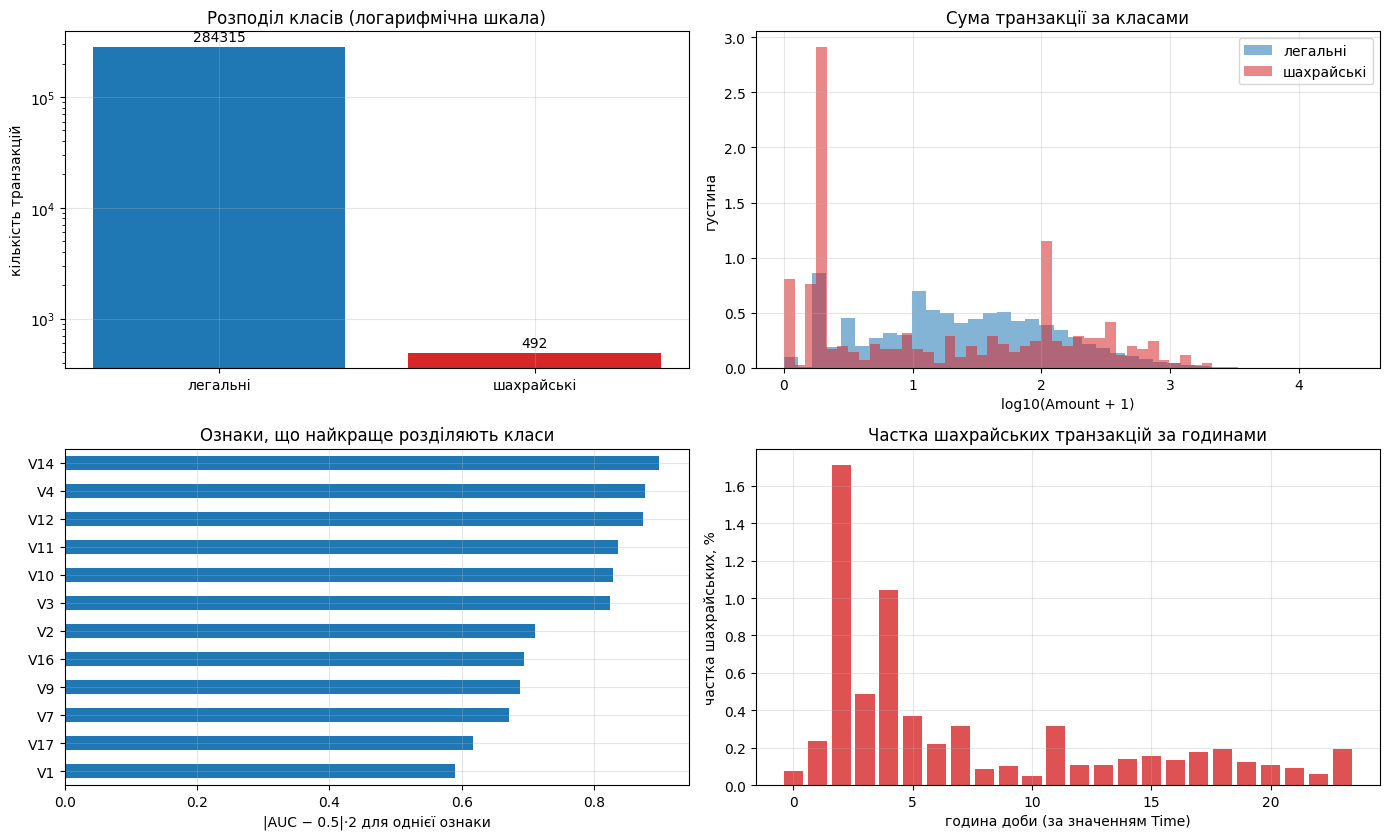

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
cnt = df["Class"].value_counts().sort_index()
ax[0, 0].bar(["легальні", "шахрайські"], cnt.values, color=["tab:blue", "tab:red"]); ax[0, 0].set_yscale("log")
ax[0, 0].bar_label(ax[0, 0].containers[0], padding=2); ax[0, 0].set_title("Розподіл класів (логарифмічна шкала)"); ax[0, 0].set_ylabel("кількість транзакцій")

for c, color, lab in [(0, "tab:blue", "легальні"), (1, "tab:red", "шахрайські")]:
    ax[0, 1].hist(np.log10(df.loc[df.Class == c, "Amount"] + 1), bins=40, density=True, alpha=0.55, color=color, label=lab)
ax[0, 1].set_xlabel("log10(Amount + 1)"); ax[0, 1].set_ylabel("густина"); ax[0, 1].set_title("Сума транзакції за класами"); ax[0, 1].legend()

sep.head(12).sort_values().plot.barh(ax=ax[1, 0], color="tab:blue"); ax[1, 0].set_xlabel("|AUC − 0.5|·2 для однієї ознаки"); ax[1, 0].set_title("Ознаки, що найкраще розділяють класи")

hour = (df["Time"] // 3600).astype(int) % 24
rate = df.groupby(hour)["Class"].mean() * 100
ax[1, 1].bar(rate.index, rate.values, color="tab:red", alpha=0.8); ax[1, 1].set_xlabel("година доби (за значенням Time)"); ax[1, 1].set_ylabel("частка шахрайських, %")
ax[1, 1].set_title("Частка шахрайських транзакцій за годинами")
plt.tight_layout(); plt.show()

**Висновок.** Таблиця містить 284 807 транзакцій без пропусків, із них лише 492 (0.17%) шахрайські, тому модель, що завжди відповідає «легальна», матиме accuracy ≈ 0.998. Шахрайські транзакції мають меншу медіанну суму (9.2 проти 22.0) і частіше трапляються на початку доби за значенням `Time` (≈ 1.7% у 2-гу та ≈ 1.0% у 4-ту годину проти 0.05–0.5% в інші години; відлік `Time` іде від першої транзакції). Поодинці найкраще їх розділяють `V14`, `V4` та `V12` (|AUC − 0.5|·2 = 0.90, 0.88, 0.87). Виявлено 1 081 повний дублікат (19 шахрайських), їх потрібно прибрати.

## 3. Підготовка даних: дублікати, ознаки, вибірки
Етапи:
1. **Повні дублікати** (однакові всі 31 значення) видаляємо.
2. **Однакові ознаки V1–V28 за різного `Time`.** Перевіряємо, чи є записи, що збігаються за всіма `V1`–`V28`, але відрізняються часом; такі записи не можуть бути різними транзакціями. Їх позначаємо номером групи, щоб надалі (A/B-тестування) не розділяти групу між навчальною і тестовою вибірками.
3. **Ознаки.** До `V1`–`V28` додаємо `LogAmount = log(1 + Amount)` (сума дуже скошена) та час доби у циклічному вигляді `HourSin`, `HourCos`. Для DBSCAN (п. 4–7) основним представленням залишаються `V1`–`V28` без змін: вони вже є компонентами PCA, а розкид кожної відображає її важливість; інші варіанти порівнюємо в п. 6.2.
4. **Вибірка для DBSCAN.** DBSCAN потребує попарних відстаней, тому на всіх 283 тис. записів його не запустити. Беремо **усі шахрайські транзакції та 10 000 випадкових легальних** (частка шахрайських у вибірці ≈ 4.5% замість реальних 0.17%; вплив цієї частки досліджуємо в п. 6.5). Через різну вибірку легальних кожен експеримент повторюємо на 3 різних вибірках.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Після видалення повних дублікатів:", df.shape, "| шахрайських:", int(df["Class"].sum()))

# записи з однаковими V1–V28 (група визначається хешем округлених значень)
df["group"] = pd.util.hash_pandas_object(df[V].round(6), index=False).values
gsize = df.groupby("group")["Class"].transform("size")
conflict = df.groupby("group")["Class"].transform("nunique") > 1
print("Записів, що мають інший запис з такими самими V1–V28:", int((gsize > 1).sum()), "| у групах:", df.loc[gsize > 1, "group"].nunique(),
      "| груп з різними мітками:", df.loc[conflict, "group"].nunique(), "| шахрайських серед них:", int(df.loc[gsize > 1, "Class"].sum()))
ex = df[gsize > 1].sort_values("group").head(4)[["Time", "V1", "V2", "Amount", "Class"]]
display(ex)

df["LogAmount"] = np.log1p(df["Amount"])
df["Hour"] = (df["Time"] // 3600) % 24
df["HourSin"], df["HourCos"] = np.sin(2 * np.pi * df["Hour"] / 24), np.cos(2 * np.pi * df["Hour"] / 24)
FEATS = V + ["LogAmount", "HourSin", "HourCos"]
N_FRAUD = int(df["Class"].sum())

def make_sample(data=None, n_legit=10_000, n_fraud=None, seed=0):
    """Вибірка: n_fraud шахрайських (за замовчуванням усі) та n_legit випадкових легальних транзакцій."""
    data = df if data is None else data
    rng = np.random.default_rng(seed)
    fr, lg = data.index[data["Class"] == 1].to_numpy(), data.index[data["Class"] == 0].to_numpy()
    if n_fraud is not None and n_fraud < len(fr):
        fr = rng.choice(fr, n_fraud, replace=False)
    return data.loc[np.r_[fr, rng.choice(lg, n_legit, replace=False)]].reset_index(drop=True)

s0 = make_sample(seed=RANDOM_STATE)
print("Вибірка для DBSCAN:", s0.shape, "| шахрайських:", int(s0["Class"].sum()), "({:.1%})".format(s0["Class"].mean()))

Після видалення повних дублікатів: (283726, 31) | шахрайських: 473
Записів, що мають інший запис з такими самими V1–V28: 12446 | у групах: 4383 | груп з різними мітками: 0 | шахрайських серед них: 0


,Time,V1,V2,Amount,Class
10678,18151.0,1.185124,-0.383987,11.85,0
12602,22164.0,1.185124,-0.383987,11.85,0
174429,122195.0,2.036823,-0.166347,9.99,0
174769,122337.0,2.036823,-0.166347,9.99,0


Вибірка для DBSCAN: (10473, 36) | шахрайських: 473 (4.5%)


**Висновок.** Після видалення повних дублікатів залишилось 283 726 транзакцій (473 шахрайські). 12 446 записів (4 383 групи) мають однакові `V1`–`V28` за різного `Time`: усі вони легальні, а мітки в межах груп не суперечать одна одній. Тому для A/B-тестування дані ділимо за групами, а вплив таких копій на DBSCAN перевіримо в п. 6.7. Вибірка для DBSCAN містить 10 473 транзакції, з них 473 (4.5%) шахрайські.

## 4. Реалізація DBSCAN
DBSCAN групує точки за щільністю. Для кожної точки визначається $\varepsilon$-окіл (усі точки на відстані $\le\varepsilon$). Точка з не менш ніж `MinPts` сусідами в околі (разом із собою) — **ядрова** і запускає кластер; усі точки, щільно-досяжні від ядрових, додаються до кластера; точка, що лежить в околі ядрової, але сама не ядрова, — **гранична**; решта — **шум** (мітка −1).

Спочатку наводимо реалізацію з методички та її приклад. Вона правильна, але на кожен запит околу заново будує `NearestNeighbors`, тому працює повільно навіть на невеликих даних. Далі пишемо ефективну реалізацію з тією ж логікою: запит околу — одне множення матриці на вектор. Перевіряємо її на прикладі з методички та порівнюємо з `sklearn.cluster.DBSCAN`.

In [6]:
class DBSCANMethodical:
    """Реалізація з методички (для порівняння)."""
    def __init__(self, eps=0.5, min_samples=5):
        self.eps, self.min_samples = eps, min_samples

    def _region_query(self, X, point_index):
        nbrs = NearestNeighbors(radius=self.eps).fit(X)          # індекс будується заново для кожного запиту
        return nbrs.radius_neighbors([X[point_index]])[1][0]

    def _expand_cluster(self, X, labels, point_index, cluster_id):
        queue = [point_index]
        while queue:
            point_index = queue.pop(0)
            if labels[point_index] == -1:
                labels[point_index] = cluster_id
            if labels[point_index] == 0:
                labels[point_index] = cluster_id
                neighbors = self._region_query(X, point_index)
                if len(neighbors) >= self.min_samples:
                    queue.extend(neighbors)

    def fit_predict(self, X):
        labels = np.zeros(len(X), dtype=int)                     # 0 — не відвідана, -1 — шум, 1, 2, ... — кластер
        cluster_id = 0
        for point_index in range(len(X)):
            if labels[point_index] != 0:
                continue
            neighbors = self._region_query(X, point_index)
            if len(neighbors) < self.min_samples:
                labels[point_index] = -1
            else:
                cluster_id += 1
                self._expand_cluster(X, labels, point_index, cluster_id)
        return labels

toy = np.array([[1, 2], [2, 2], [2, 3], [8, 7], [8, 8], [25, 80]])
print("Мітки кластерів (приклад з методички):", DBSCANMethodical(eps=3, min_samples=2).fit_predict(toy))

Мітки кластерів (приклад з методички): [ 1  1  1  2  2 -1]


In [7]:
class DBSCANScratch:
    """DBSCAN з тією ж логікою, але ε-окіл знаходиться одним множенням матриці на вектор; кожна точка опитується не більше одного разу."""
    def __init__(self, eps=0.5, min_samples=5):
        self.eps, self.min_samples = eps, min_samples

    def fit_predict(self, X):
        X = np.asarray(X, dtype=float)
        sq, eps2 = (X ** 2).sum(axis=1), self.eps ** 2

        def region(i):                                           # індекси точок в ε-околі точки i (разом із нею)
            return np.flatnonzero(sq + sq[i] - 2 * (X @ X[i]) <= eps2)

        labels = np.zeros(len(X), dtype=int)                     # 0 — не відвідана, -1 — шум, 1, 2, ... — кластер
        cluster_id = 0
        for i in range(len(X)):
            if labels[i] != 0:
                continue
            neighbors = region(i)
            if len(neighbors) < self.min_samples:
                labels[i] = -1
                continue
            cluster_id += 1
            labels[i] = cluster_id
            queue = deque([i])
            while queue:
                j = queue.popleft()
                nb = neighbors if j == i else region(j)
                if len(nb) < self.min_samples:                   # j — гранична точка: її сусідів не додаємо
                    continue
                fresh = nb[labels[nb] <= 0]                      # ще не відвідані точки та шум
                queue.extend(fresh[labels[fresh] == 0])          # у чергу — лише ті, що ще не в черзі
                labels[fresh] = cluster_id
        self.labels_ = labels
        return labels

mine, ref = DBSCANScratch(eps=3, min_samples=2).fit_predict(toy), DBSCAN(eps=3, min_samples=2).fit_predict(toy)
print("Мітки кластерів (наша реалізація):", mine)
print("Мітки кластерів (sklearn):        ", ref, "(нумерація з 0, у нашій реалізації — з 1)")
print("ARI між ними:", adjusted_rand_score(mine, ref))

Мітки кластерів (наша реалізація): [ 1  1  1  2  2 -1]
Мітки кластерів (sklearn):         [ 0  0  0  1  1 -1] (нумерація з 0, у нашій реалізації — з 1)
ARI між ними: 1.0


Перевіряємо реалізацію на реальних даних (ознаки `V1`–`V28`, `MinPts = 56`): вибірка з 800 точок — для порівняння з методичною реалізацією (вона дуже повільна), вибірка з 2 473 точок — для порівняння з sklearn, для двох значень $\varepsilon$ (при нижчому утворюються два кластери). Порівнюємо мітки (ARI = 1 означає однакове розбиття), множину шумових точок і час роботи.

In [8]:
def time_it(fn):
    t0 = time.perf_counter(); out = fn(); return out, time.perf_counter() - t0

rows = {}
for n_legit, with_method, pct in [(400, True, 95), (2000, False, 50), (2000, False, 95)]:
    Xc = make_sample(n_legit=n_legit, n_fraud=400 if with_method else None, seed=1)[V].to_numpy()
    eps = np.percentile(NearestNeighbors(n_neighbors=56).fit(Xc).kneighbors(Xc)[0][:, -1], pct)     # ε — перцентиль відстані до 56-го сусіда
    lab_sk, t_sk = time_it(lambda: DBSCAN(eps=eps, min_samples=56).fit_predict(Xc))
    lab_my, t_my = time_it(lambda: DBSCANScratch(eps=eps, min_samples=56).fit_predict(Xc))
    row = {"точок": len(Xc), "ε": eps, "кластерів": len(set(lab_my)) - int((lab_my == -1).any()), "шум, %": (lab_my == -1).mean() * 100,
           "ARI(наша, sklearn)": adjusted_rand_score(lab_sk, lab_my), "шум збігається": bool(((lab_sk == -1) == (lab_my == -1)).all()),
           "час sklearn, с": t_sk, "час наша, с": t_my}
    if with_method:
        lab_me, t_me = time_it(lambda: DBSCANMethodical(eps=eps, min_samples=56).fit_predict(Xc))
        row.update({"ARI(методичка, sklearn)": adjusted_rand_score(lab_sk, lab_me), "час методичка, с": t_me})
    rows[f"n = {len(Xc)}, ε = {pct}-й перцентиль"] = row
display(pd.DataFrame(rows).T.round(3))

,точок,ε,кластерів,"шум, %","ARI(наша, sklearn)",шум збігається,"час sklearn, с","час наша, с","ARI(методичка, sklearn)","час методичка, с"
"n = 800, ε = 95-й перцентиль",800,21.026648,1,1.375,1.0,True,0.016384,0.021951,1.0,33.603429
"n = 2473, ε = 50-й перцентиль",2473,4.138579,2,29.55924,1.0,True,0.050307,0.102588,NaN,NaN
"n = 2473, ε = 95-й перцентиль",2473,16.017921,1,3.922362,1.0,True,0.154816,0.111121,NaN,NaN


### Оцінка «шумовості» для всіх $\varepsilon$ одразу
Для заданого `MinPts` кожна точка стає не-шумовою, починаючи з певного $\varepsilon$: точка не шум, якщо вона ядрова (її $\varepsilon\ge k_d$, де $k_d$ — відстань до `MinPts`-го сусіда, рахуючи її саму) або лежить в околі ядрової точки $j$ (тоді $\varepsilon\ge d(i,j)$ та $\varepsilon\ge k_{d,j}$). Тому найменше таке $\varepsilon$ дорівнює $s_i=\min_j \max(d(i,j),\,k_{d,j})$, а шумом при заданому $\varepsilon$ є точки з $s_i>\varepsilon$. Величина $s_i$ — це ранжування точок за аномальністю: чим вона більша, тим «самотніша» точка. Це дозволяє оцінювати DBSCAN як детектор без підбору $\varepsilon$ (ROC-AUC за $s_i$) і швидко перебирати параметри в п. 6. Перевіряємо, що множина шуму збігається з результатом DBSCAN для кількох $\varepsilon$.

In [9]:
def noise_score(X, min_samples, metric="euclidean", block=2000):
    """s_i — найменше ε, за якого точка i вже не є шумом у DBSCAN (min_samples фіксоване)."""
    n = len(X)
    kd = np.empty(n, dtype=np.float32)
    for s in range(0, n, block):                                 # відстань до min_samples-го сусіда (разом із самою точкою)
        D = pairwise_distances(X[s:s + block], X, metric=metric).astype(np.float32)
        kd[s:s + block] = np.partition(D, min_samples - 1, axis=1)[:, min_samples - 1]
    score = np.empty(n, dtype=np.float32)
    for s in range(0, n, block):
        D = pairwise_distances(X[s:s + block], X, metric=metric).astype(np.float32)
        score[s:s + block] = np.maximum(D, kd[None, :]).min(axis=1)      # min_j max(d(i, j), kd_j)
    return score

MIN_PTS = 2 * len(V)                                             # правило 2·D, D — кількість ознак; тут 56
X0, y0 = s0[V].to_numpy(), s0["Class"].to_numpy()
sc0 = noise_score(X0, MIN_PTS)
ss = np.sort(sc0)
gaps = np.flatnonzero(np.diff(ss) > 1e-4)                        # місця, де сусідні значення s справді різні
rows = []
for q in [0.02, 0.05, 0.10, 0.20]:
    i = gaps[np.searchsorted(gaps, int((1 - q) * len(ss)))]      # найближче до частки q місце між різними значеннями
    eps = float((ss[i] + ss[i + 1]) / 2)                         # ε посередині між ними, щоб уникнути збігів на межі
    lab = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X0)
    rows.append({"ε": eps, "шум за DBSCAN, %": (lab == -1).mean() * 100, "шум за оцінкою s, %": (sc0 > eps).mean() * 100,
                 "множини шуму збігаються": bool(((lab == -1) == (sc0 > eps)).all())})
display(pd.DataFrame(rows).round(3))

,ε,"шум за DBSCAN, %","шум за оцінкою s, %",множини шуму збігаються
0,8.762,1.996,1.996,True
1,6.334,4.994,4.994,True
2,4.370,9.997,9.997,True
3,3.412,19.994,19.994,True


**Висновок.** Наша реалізація дає ті самі кластери, що й методична та `sklearn` (ARI = 1, множини шуму збігаються) на прикладі з методички та на реальних даних, зокрема при двох кластерах (n = 2 473, ε = 4.14). Нумерація кластерів у `sklearn` починається з 0, у нашій реалізації — з 1, розбиття те саме. На 800 точках методична реалізація працює ≈ 27 с проти ≈ 0.01 с у нашої та `sklearn`, бо будує `NearestNeighbors` заново для кожного запиту; на 2 473 точках наша реалізація та `sklearn` працюють за 0.02–0.1 с (час залежить від машини). Оцінка шумовості $s_i$ дає множину шуму, що точно збігається з DBSCAN при всіх чотирьох перевірених ε (шум 2%, 5%, 10%, 20%), тому далі її використовуємо для швидкого порівняння варіантів.

## 5. DBSCAN як детектор шахрайства: базова модель
Параметри базової моделі: ознаки `V1`–`V28` без змін; `MinPts = 2·D = 56` (D = 28 — кількість ознак). Радіус $\varepsilon$ вибираємо за графіком відстаней до 56-го сусіда, відсортованих за зростанням: «ліктем» (точкою найбільшого відхилення від прямої, що з'єднує кінці кривої) вважаємо місце, де відстані різко зростають, тобто починаються рідкі області. Шумом DBSCAN вважає точки поза щільними областями, тому якість оцінюємо так: яка частка шахрайських транзакцій потрапила в шум (recall) і яка частка шуму — шахрайські (precision). Мітки класів при цьому в алгоритмі не використовуються.

In [10]:
def elbow(curve):
    """Індекс точки кривої, найбільш віддаленої від хорди між її кінцями."""
    x = np.linspace(0, 1, len(curve)); yy = (curve - curve[0]) / (curve[-1] - curve[0])
    return int(np.argmax((x - yy) / np.sqrt(2)))

kd = np.sort(NearestNeighbors(n_neighbors=MIN_PTS).fit(X0).kneighbors(X0)[0][:, -1])
eps_elbow = float(kd[elbow(kd)])

def dbscan_report(eps, X=X0, y=y0, min_samples=MIN_PTS):
    lab = DBSCANScratch(eps=eps, min_samples=min_samples).fit_predict(X)
    nz = lab == -1
    rec, prec = nz[y == 1].mean(), (y[nz].mean() if nz.any() else np.nan)
    return lab, {"ε": eps, "кластерів": len(set(lab)) - int(nz.any()), "найбільший кластер, %": np.bincount(lab[~nz]).max() / len(lab) * 100 if (~nz).any() else 0,
                 "шум, %": nz.mean() * 100, "recall шахрайських у шумі": rec, "precision шуму": prec, "F1": 2 * rec * prec / (rec + prec) if rec + prec > 0 else 0}

grid_eps = [3, 4, 5, 6, 7, 8, 10, 12, 16]
sweep = pd.DataFrame([dbscan_report(e)[1] for e in grid_eps]).set_index("ε")
print(f"ε за ліктем кривої k-відстаней: {eps_elbow:.2f}")
display(pd.concat([sweep, pd.DataFrame([dbscan_report(eps_elbow)[1]]).set_index("ε")]).round(3))
eps_best = float(sweep["F1"].idxmax())
print("ε з найкращим F1 серед перевірених:", eps_best)

ε за ліктем кривої k-відстаней: 9.31


,кластерів,"найбільший кластер, %","шум, %",recall шахрайських у шумі,precision шуму,F1
ε,,,,,,
3.000000,3,63.076,32.522,0.943,0.131,0.230
4.000000,1,87.702,12.298,0.884,0.325,0.475
5.000000,1,92.342,7.658,0.844,0.498,0.626
6.000000,2,93.736,5.681,0.704,0.560,0.624
7.000000,1,95.980,4.020,0.541,0.608,0.573
8.000000,1,97.412,2.588,0.357,0.624,0.454
10.000000,1,98.472,1.528,0.247,0.731,0.370
12.000000,1,98.759,1.241,0.218,0.792,0.342
16.000000,1,98.978,1.022,0.195,0.860,0.317


ε з найкращим F1 серед перевірених: 5.0


Склад кластерів при ε = 5.0 (кластер -1 — шум):


,точок,шахрайських,частка шахрайських
кластер,,,
-1,802,399,0.498
1,9671,74,0.008


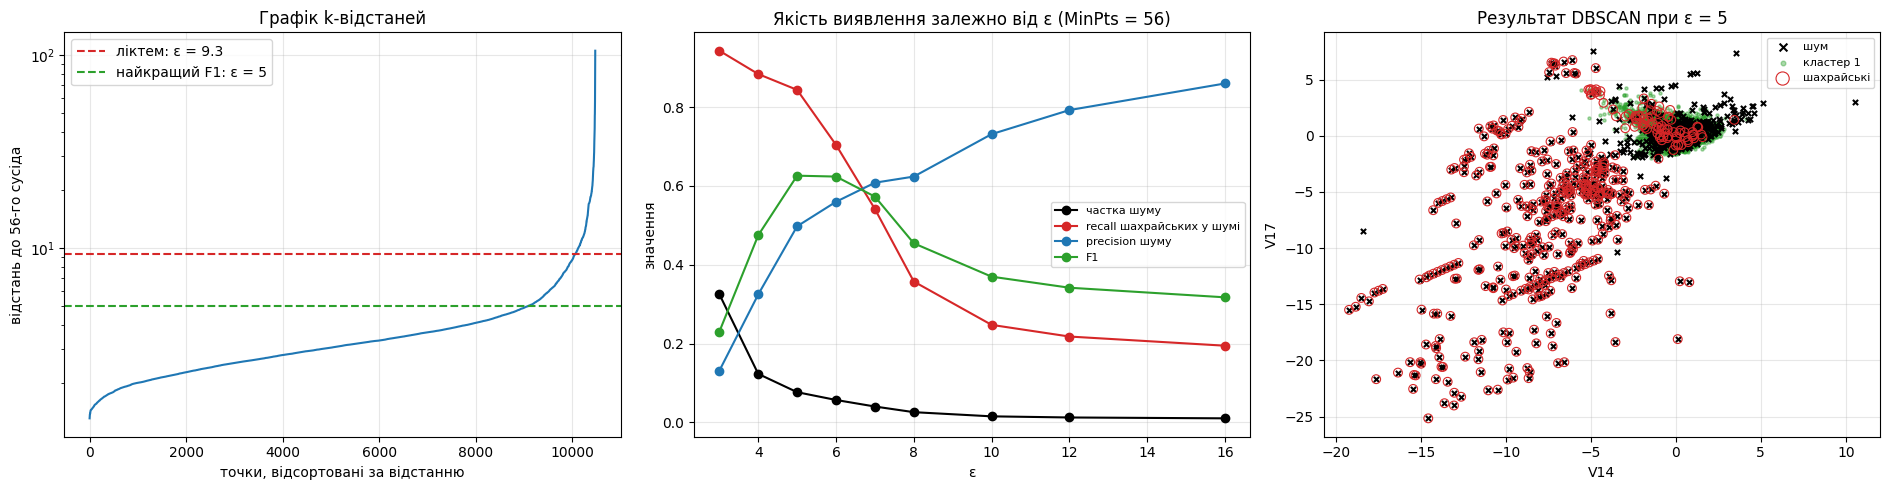

In [11]:
lab_el, rep_el = dbscan_report(eps_elbow)
lab_best, rep_best = dbscan_report(eps_best)
print("Склад кластерів при ε =", eps_best, "(кластер -1 — шум):")
comp = pd.DataFrame({"кластер": lab_best, "шахрайська": y0}).groupby("кластер")["шахрайська"].agg(точок="size", шахрайських="sum")
comp["частка шахрайських"] = comp["шахрайських"] / comp["точок"]
display(comp.round(3))

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].plot(np.arange(len(kd)), kd, color="tab:blue"); ax[0].axhline(eps_elbow, color="tab:red", ls="--", label=f"ліктем: ε = {eps_elbow:.1f}")
ax[0].axhline(eps_best, color="tab:green", ls="--", label=f"найкращий F1: ε = {eps_best:g}"); ax[0].set_yscale("log"); ax[0].legend()
ax[0].set_xlabel("точки, відсортовані за відстанню"); ax[0].set_ylabel("відстань до 56-го сусіда"); ax[0].set_title("Графік k-відстаней")

for col, color in [("шум, %", "black"), ("recall шахрайських у шумі", "tab:red"), ("precision шуму", "tab:blue"), ("F1", "tab:green")]:
    vals = sweep[col] / 100 if col == "шум, %" else sweep[col]
    ax[1].plot(sweep.index, vals, marker="o", color=color, label="частка шуму" if col == "шум, %" else col)
ax[1].set_xlabel("ε"); ax[1].set_ylabel("значення"); ax[1].set_title("Якість виявлення залежно від ε (MinPts = 56)"); ax[1].legend(fontsize=8)

palette = {1: "tab:green", 2: "tab:orange", 3: "tab:purple", 4: "tab:brown"}
for c in sorted(set(lab_best)):
    m = lab_best == c
    if c == -1:
        ax[2].scatter(X0[m, V.index("V14")], X0[m, V.index("V17")], s=14, marker="x", color="black", label="шум", zorder=2)
    else:
        ax[2].scatter(X0[m, V.index("V14")], X0[m, V.index("V17")], s=5, alpha=0.4, color=palette.get(c, "gray"), label=f"кластер {c}", zorder=1)
f = y0 == 1
ax[2].scatter(X0[f, V.index("V14")], X0[f, V.index("V17")], s=40, facecolors="none", edgecolors="tab:red", linewidths=0.8, label="шахрайські", zorder=3)
ax[2].set_xlabel("V14"); ax[2].set_ylabel("V17"); ax[2].set_title(f"Результат DBSCAN при ε = {eps_best:g}"); ax[2].legend(fontsize=8, markerscale=1.5)
plt.tight_layout(); plt.show()

**Висновок.** ε за «ліктем» кривої k-відстаней (9.31) дає лише 1.7% шуму: у ньому 25.6% шахрайських транзакцій з precision 0.665, тобто знаходяться лише найвіддаленіші викиди. З ростом ε частка шуму падає з 32.5% (ε = 3) до 1.0% (ε = 16), recall падає з 0.94 до 0.20, а precision зростає з 0.13 до 0.86; найкращий F1 = 0.626 при ε = 5 (шуму 7.7%, recall 0.844, precision 0.498), при ε = 6 F1 майже такий самий (0.624, recall 0.704, precision 0.560). При ε = 5 утворюється один кластер із 9 671 точки, де шахрайських лише 0.8%, а шум із 802 точок містить 399 із 473 шахрайських транзакцій (49.8% проти 4.5% у вибірці, збагачення ≈ 11 разів). Тобто DBSCAN без міток справді відділяє значну частину шахрайських транзакцій, а ε треба підбирати під баланс між повнотою та точністю, бо ліктем для цього не підходить. На проєкції V14–V17 частина шумових точок лежить усередині щільної області, бо відрізняється іншими ознаками.

## 6. Залежність якості DBSCAN від параметрів та особливостей даних
Щоб порівнювати варіанти без підбору $\varepsilon$ для кожного, використовуємо оцінку $s_i$ з п. 4 і метрики на всій вибірці: **ROC-AUC** (наскільки шахрайські транзакції мають вищу «шумовість» $s_i$ за легальні; 0.5 — випадково, 1 — ідеально) та **precision@K** (частка шахрайських серед $K$ найбільш шумових точок, де $K$ — кількість шахрайських у вибірці). Змінюємо по одному фактору, решта — як у базовій моделі (`V1`–`V28`, `MinPts = 56`, евклідова відстань, усі шахрайські та 10 000 легальних). Кожен варіант усереднюється по 3 різних вибірках легальних транзакцій; ± — розкид ROC-AUC між вибірками. Підсумкові значення ROC-AUC збираємо в `FACTORS`.

In [12]:
def evaluate_score(score, y, share=0.05):
    """Якість ранжування точок за «аномальністю»: ROC-AUC, PR-AUC, precision@K (K — кількість шахрайських) та recall серед share найбільш аномальних."""
    K, order = int(y.sum()), np.argsort(-score, kind="stable")
    flagged = np.zeros(len(y), dtype=bool)
    flagged[order[:int(round(share * len(y)))]] = True
    return {"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score), "precision@K": y[order[:K]].mean(), "recall@5%": flagged[y == 1].mean()}

SEEDS = (0, 1, 2)
def dbscan_quality(make_X, min_samples=MIN_PTS, metric="euclidean", seeds=SEEDS, **sample_kw):
    """Середня якість оцінки s_i за кількома вибірками; make_X(sample, seed) повертає матрицю ознак."""
    rows = []
    for sd in seeds:
        s = make_sample(seed=sd, **sample_kw)
        rows.append(evaluate_score(noise_score(make_X(s, sd), min_samples, metric), s["Class"].to_numpy()))
    r = pd.DataFrame(rows)
    return {**r.mean().to_dict(), "± ROC-AUC": r["ROC-AUC"].std()}

raw_V = lambda s, sd: s[V].to_numpy()
BASE = dbscan_quality(raw_V)
print("Базова конфігурація:", {k: round(v, 4) for k, v in BASE.items()})
FACTORS = {}
tbl = lambda res: pd.DataFrame(res).T[["ROC-AUC", "± ROC-AUC", "precision@K", "PR-AUC"]]

Базова конфігурація: {'ROC-AUC': 0.9469, 'PR-AUC': 0.6123, 'precision@K': 0.6307, 'recall@5%': 0.6843, '± ROC-AUC': 0.0002}


### 6.1. Параметр MinPts
Мале `MinPts` робить щільними навіть невеликі групи випадкових точок, тому шум майже зникає лише для найбільш віддалених викидів; велике — вимагає щільнішого оточення.

,ROC-AUC,± ROC-AUC,precision@K,PR-AUC
MinPts,,,,
3,0.8459,0.0021,0.3587,0.2644
5,0.9104,0.0014,0.4207,0.3347
10,0.9398,0.0008,0.5426,0.4548
20,0.9446,0.0002,0.5962,0.5297
56,0.9469,0.0002,0.6307,0.6123
100,0.9482,0.0006,0.6963,0.6538
200,0.9468,0.0005,0.6906,0.6893
400,0.9453,0.0001,0.6899,0.6990


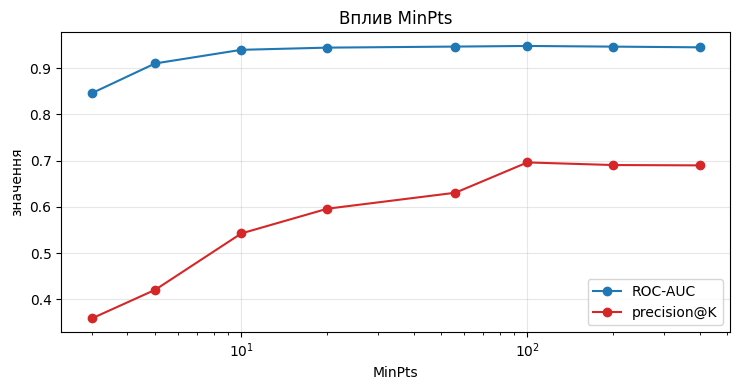

In [13]:
MINPTS = [3, 5, 10, 20, 56, 100, 200, 400]
res_mp = {m: dbscan_quality(raw_V, min_samples=m) for m in MINPTS}
FACTORS["MinPts"] = pd.Series({m: r["ROC-AUC"] for m, r in res_mp.items()})
display(tbl(res_mp).rename_axis("MinPts").round(4))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(MINPTS, [r["ROC-AUC"] for r in res_mp.values()], marker="o", color="tab:blue", label="ROC-AUC")
ax.plot(MINPTS, [r["precision@K"] for r in res_mp.values()], marker="o", color="tab:red", label="precision@K")
ax.set_xscale("log"); ax.set_xlabel("MinPts"); ax.set_ylabel("значення"); ax.set_title("Вплив MinPts"); ax.legend(); plt.tight_layout(); plt.show()

**Висновок.** При `MinPts` = 3 ROC-AUC лише 0.846, а precision@K — 0.359: випадкові сусідні точки утворюють щільні групи й шум не відрізняється від норми. З ростом `MinPts` якість швидко підвищується (0.910 при 5, 0.940 при 10) і виходить на плато: 0.945–0.948 для `MinPts` від 20 до 400, максимум 0.948 при 100. precision@K зростає з 0.36 до 0.70 (при 100–400), PR-AUC продовжує рости до 0.699 при 400. Правило `MinPts` = 2·D = 56 потрапляє на плато; розкид між вибірками ≈ 0.002 або менше.

### 6.2. Масштабування та набір ознак
DBSCAN працює з евклідовою відстанню, тому ознаки з великим розкидом домінують. Порівнюємо: `V1`–`V28` без змін; z-оцінка; `V1`–`V28` разом із сумою `Amount` без масштабування (розкид суми — сотні, `V` — одиниці); `V1`–`V28`, `LogAmount`, час доби — усе з z-оцінкою.

,ROC-AUC,± ROC-AUC,precision@K,PR-AUC
V1–V28 без змін,0.9469,0.0002,0.6307,0.6123
"V1–V28, z-оцінка",0.9365,0.0002,0.5765,0.5324
V1–V28 + Amount без масштабування,0.8818,0.0014,0.2241,0.2185
"V1–V28 + LogAmount + час доби, z-оцінка",0.9388,0.0012,0.5863,0.5451


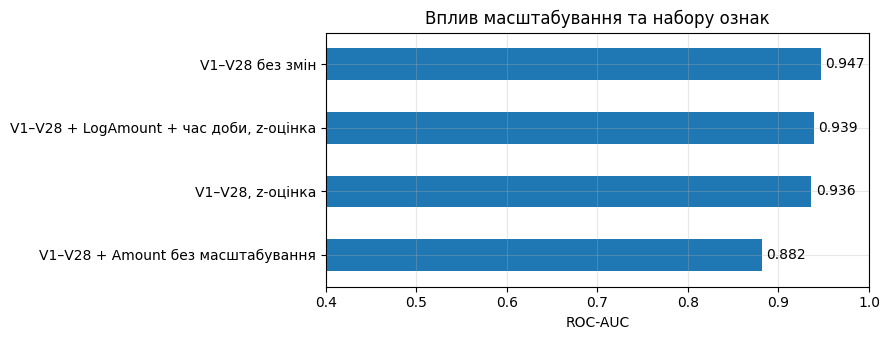

In [14]:
def zs(a):
    return StandardScaler().fit_transform(a)
SCALING = {"V1–V28 без змін": raw_V,
           "V1–V28, z-оцінка": lambda s, sd: zs(s[V]),
           "V1–V28 + Amount без масштабування": lambda s, sd: np.c_[s[V].to_numpy(), s["Amount"].to_numpy()],
           "V1–V28 + LogAmount + час доби, z-оцінка": lambda s, sd: zs(s[FEATS])}
res_sc = {k: dbscan_quality(f) for k, f in SCALING.items()}
FACTORS["Масштабування та набір ознак"] = pd.Series({k: r["ROC-AUC"] for k, r in res_sc.items()})
display(tbl(res_sc).round(4))
ax = FACTORS["Масштабування та набір ознак"].sort_values().plot.barh(figsize=(9, 3.5), color="tab:blue")
ax.set_xlabel("ROC-AUC"); ax.set_xlim(0.4, 1); ax.set_title("Вплив масштабування та набору ознак"); ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); plt.tight_layout(); plt.show()

**Висновок.** Найкраще працюють ознаки `V1`–`V28` без змін (ROC-AUC 0.947, PR-AUC 0.612). Стандартизація знижує якість до 0.937 (PR-AUC 0.532), бо вирівнює вплив усіх компонент PCA, тоді як у вихідному вигляді розкид кожної компоненти відображає її важливість. Додавання `Amount` без масштабування різко погіршує результат (ROC-AUC 0.882, precision@K 0.224): сума (сотні) домінує у відстані. Варіант із `LogAmount` і часом доби зі стандартизацією (0.939) практично збігається зі стандартизованими `V1`–`V28` (0.937), тож ці дві ознаки користі не додають.

### 6.3. Кількість ознак та шумові ознаки
У високовимірному просторі відстані між точками стають схожими («прокляття розмірності»). Перевіряємо два варіанти: (а) беремо лише перші `d` компонент `V1`–`Vd` (вони найважливіші за дисперсією PCA); (б) додаємо до всіх `V1`–`V28` нормально розподілені шумові ознаки, що не несуть інформації.

ROC-AUC  ± ROC-AUC  precision@K  PR-AUC
перші d ознак (MinPts = 2d)        2    0.8872     0.0049       0.4066  0.3354
                                   5    0.9227     0.0008       0.5025  0.4301
                                   10   0.9300     0.0005       0.4736  0.4601
                                   15   0.9479     0.0006       0.6011  0.5582
                                   20   0.9508     0.0003       0.6547  0.6177
                                   28   0.9469     0.0002       0.6307  0.6123
додані шумові ознаки (MinPts = 56) 0    0.9469     0.0002       0.6307  0.6123
                                   10   0.9443     0.0021       0.6314  0.6105
                                   28   0.9430     0.0012       0.6371  0.6087
                                   56   0.9409     0.0003       0.6321  0.6111

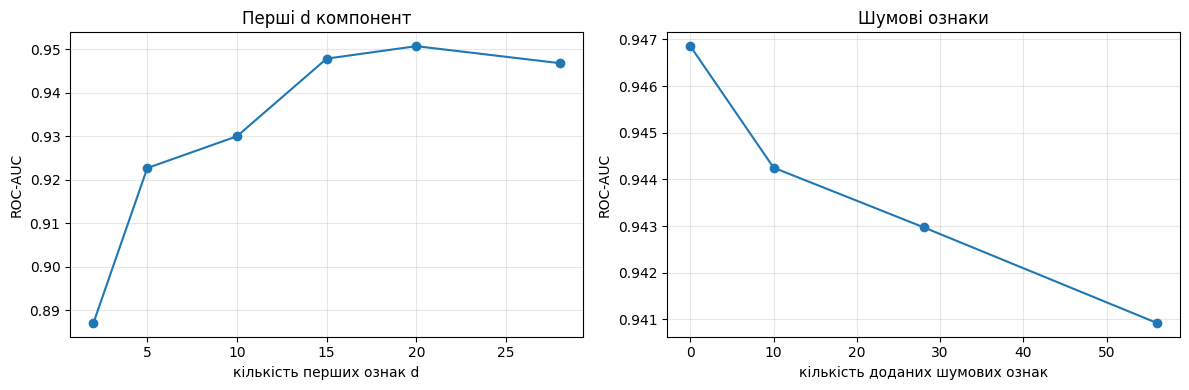

In [15]:
DIMS = [2, 5, 10, 15, 20, 28]
res_d = {d: dbscan_quality(lambda s, sd, d=d: s[V[:d]].to_numpy(), min_samples=2 * d) for d in DIMS}      # MinPts = 2·d
NOISE_K = [0, 10, 28, 56]
res_n = {k: dbscan_quality(lambda s, sd, k=k: np.c_[s[V].to_numpy(), np.random.default_rng(100 + sd).standard_normal((len(s), k))]) for k in NOISE_K}
FACTORS["Кількість ознак (перші d)"] = pd.Series({d: r["ROC-AUC"] for d, r in res_d.items()})
FACTORS["Шумові ознаки"] = pd.Series({k: r["ROC-AUC"] for k, r in res_n.items()})
display(pd.concat({"перші d ознак (MinPts = 2d)": tbl(res_d).rename_axis("d"), "додані шумові ознаки (MinPts = 56)": tbl(res_n).rename_axis("шумових ознак")}, axis=0).round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(DIMS, [r["ROC-AUC"] for r in res_d.values()], marker="o", color="tab:blue"); ax[0].set_xlabel("кількість перших ознак d"); ax[0].set_ylabel("ROC-AUC"); ax[0].set_title("Перші d компонент")
ax[1].plot(NOISE_K, [r["ROC-AUC"] for r in res_n.values()], marker="o", color="tab:blue"); ax[1].set_xlabel("кількість доданих шумових ознак"); ax[1].set_ylabel("ROC-AUC"); ax[1].set_title("Шумові ознаки")
plt.tight_layout(); plt.show()

**Висновок.** Якість росте з кількістю перших компонент: ROC-AUC 0.887 (d = 2), 0.923 (5), 0.930 (10), 0.948 (15), максимум 0.951 при d = 20; на 28 компонентах 0.947, тобто останні компоненти нічого не додають. Шумові ознаки погіршують результат лише трохи: навіть 56 зайвих нормально розподілених ознак (удвічі більше, ніж справжніх) знижують ROC-AUC з 0.947 до 0.941. Імовірно, шум приблизно однаково збільшує відстані між усіма точками, а ранжування залежить від відносної щільності.

### 6.4. Метрика відстані
Евклідова відстань — стандартний вибір. Порівнюємо з манхеттенською, відстанню Чебишова (максимум за ознаками) та косинусною (залежить лише від напрямку вектора, а не від його довжини).

,ROC-AUC,± ROC-AUC,precision@K,PR-AUC
евклідова,0.9469,0.0002,0.6307,0.6123
манхеттенська,0.9474,0.0006,0.6321,0.6182
Чебишова,0.9453,0.0007,0.6378,0.6058
косинусна,0.1349,0.0031,0.0254,0.0269


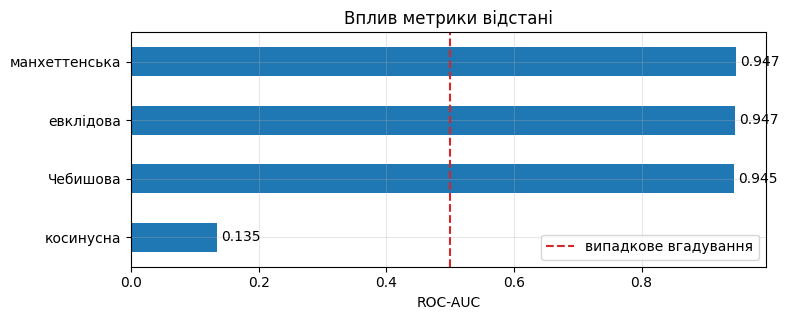

In [16]:
METRICS = {"евклідова": "euclidean", "манхеттенська": "manhattan", "Чебишова": "chebyshev", "косинусна": "cosine"}
res_m = {k: dbscan_quality(raw_V, metric=m) for k, m in METRICS.items()}
FACTORS["Метрика відстані"] = pd.Series({k: r["ROC-AUC"] for k, r in res_m.items()})
display(tbl(res_m).round(4))
ax = FACTORS["Метрика відстані"].sort_values().plot.barh(figsize=(8, 3.3), color="tab:blue")
ax.axvline(0.5, color="tab:red", ls="--", label="випадкове вгадування"); ax.set_xlabel("ROC-AUC"); ax.set_title("Вплив метрики відстані"); ax.legend(loc="lower right")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); plt.tight_layout(); plt.show()

**Висновок.** Евклідова (0.947), манхеттенська (0.947) та відстань Чебишова (0.945) дають практично однакову якість. Косинусна відстань дає ROC-AUC 0.135, тобто ранжування навіть інвертоване (precision@K 0.025 нижче за частку шахрайських 0.045): вона не враховує довжину вектора, а вектори шахрайських транзакцій, імовірно, відрізняються саме віддаленістю від центру, тоді як за напрямком вони утворюють щільні групи. Для DBSCAN на цих даних вимір довжини важливий, тому косинусну відстань використовувати не можна.

### 6.5. Частка шахрайських транзакцій у вибірці
У реальності шахрайських транзакцій 0.17%. Якщо їх багато, вони можуть утворювати власні щільні групи й переставати бути шумом. Залишаємо 10 000 легальних і беремо різну кількість шахрайських (від 17, що відповідає реальній частці, до всіх).

In [17]:
NFR = [17, 50, 100, 250, N_FRAUD]
res_p = {f"{n} ({n / (n + 10_000):.1%})": dbscan_quality(raw_V, n_fraud=n) for n in NFR}
FACTORS["Частка шахрайських у вибірці"] = pd.Series({k: r["ROC-AUC"] for k, r in res_p.items()})
display(tbl(res_p).rename_axis("шахрайських (частка у вибірці)").round(4))

,ROC-AUC,± ROC-AUC,precision@K,PR-AUC
шахрайських (частка у вибірці),,,,
17 (0.2%),0.9671,0.0206,0.2745,0.2632
50 (0.5%),0.9539,0.0077,0.4200,0.3953
100 (1.0%),0.9434,0.0220,0.5267,0.4504
250 (2.4%),0.9564,0.0052,0.5560,0.5608
473 (4.5%),0.9469,0.0002,0.6307,0.6123


**Висновок.** ROC-AUC майже не залежить від кількості шахрайських транзакцій у вибірці (0.943–0.967 без чіткого тренду, розкид між вибірками до ±0.02 при малій їх кількості), тоді як практична точність залежить сильно: precision@K зростає з 0.27 (17 шахрайських, 0.2% — як у реальності) до 0.63 (473, 4.5%), PR-AUC — з 0.26 до 0.61. Отже, ранжування за DBSCAN має однакову якість, але на реальній частці шахрайських серед позначених як шум буде лише ≈ чверть справжніх, а оцінка на збагаченій вибірці (4.5%) завищує precision.

### 6.6. Розмір вибірки
Більше точок — щільніші області й надійніша оцінка щільності, але й значно більший час розрахунку (попарні відстані). Змінюємо кількість легальних транзакцій у вибірці (усі шахрайські залишаються); `MinPts` не змінюємо, для найбільшої вибірки беремо 2 повторення.

In [18]:
NLEG = [2_000, 5_000, 10_000, 20_000]
res_n_leg = {}
for n in NLEG:
    t0 = time.perf_counter()
    res_n_leg[n] = {**dbscan_quality(raw_V, n_legit=n, seeds=SEEDS if n < 20_000 else SEEDS[:2]), "час, с": (time.perf_counter() - t0) / (3 if n < 20_000 else 2)}
FACTORS["Розмір вибірки (легальних)"] = pd.Series({n: r["ROC-AUC"] for n, r in res_n_leg.items()})
display(pd.DataFrame(res_n_leg).T[["ROC-AUC", "± ROC-AUC", "precision@K", "PR-AUC", "час, с"]].rename_axis("легальних").round(4))

,ROC-AUC,± ROC-AUC,precision@K,PR-AUC,"час, с"
легальних,,,,,
2000,0.9380,0.0023,0.8379,0.8195,0.1953
5000,0.9429,0.0019,0.7075,0.7166,0.7530
10000,0.9469,0.0002,0.6307,0.6123,2.5965
20000,0.9504,0.0002,0.5317,0.5085,10.2214


**Висновок.** Більша вибірка дає трохи вищий ROC-AUC (0.938 при 2 000 легальних, 0.943 при 5 000, 0.947 при 10 000, 0.950 при 20 000). precision@K при цьому падає (0.84 → 0.53), бо падає частка шахрайських у вибірці (19% → 2.3%), а не через гіршу роботу алгоритму. Час зростає приблизно квадратично: при подвоєнні легальних з 10 000 до 20 000 він збільшився з ≈ 1.6 до ≈ 8 с (залежить від машини), тому на всіх 283 тис. записів прямий запуск непрактичний.

### 6.7. Повторні записи з однаковими V1–V28
У п. 3 виявлено записи, що збігаються за всіма `V1`–`V28` (усі — легальні). Такі копії створюють штучну щільність: у точки з копією є сусід на нульовій відстані. Порівнюємо вибірки з такими записами та без них (залишаємо по одному запису з групи).

In [19]:
df_nodup = df.drop_duplicates(subset=V).reset_index(drop=True)
print("Записів без повторів V1–V28:", len(df_nodup), "| шахрайських:", int(df_nodup["Class"].sum()))
res_dup = {"із повторами (як є)": dbscan_quality(raw_V), "без повторів": dbscan_quality(raw_V, data=df_nodup)}
FACTORS["Повторні записи V1–V28"] = pd.Series({k: r["ROC-AUC"] for k, r in res_dup.items()})
display(tbl(res_dup).round(4))

Записів без повторів V1–V28: 275663 | шахрайських: 473


,ROC-AUC,± ROC-AUC,precision@K,PR-AUC
із повторами (як є),0.9469,0.0002,0.6307,0.6123
без повторів,0.9459,0.0004,0.6195,0.6109


**Висновок.** Записи з однаковими `V1`–`V28` майже не впливають на результат: ROC-AUC 0.947 з повторами та 0.946 без них, PR-AUC 0.612 та 0.611. Копії складають лише 4.4% записів і є лише серед легальних транзакцій; їх видалення можна не проводити, але у вибірки для A/B-тестування вони не повинні потрапляти одночасно в навчання й тест.

### 6.8. Зведення: які фактори впливають найсильніше
Для кожного фактора — мінімальне та максимальне значення ROC-AUC серед перевірених варіантів; «розмах» показує чутливість до цього фактора.

,min,max,розмах
Повторні записи V1–V28,0.9459,0.9469,0.0010
Шумові ознаки,0.9409,0.9469,0.0059
Розмір вибірки (легальних),0.9380,0.9504,0.0124
Частка шахрайських у вибірці,0.9434,0.9671,0.0237
Кількість ознак (перші d),0.8872,0.9508,0.0636
Масштабування та набір ознак,0.8818,0.9469,0.0651
MinPts,0.8459,0.9482,0.1023
Метрика відстані,0.1349,0.9474,0.8126


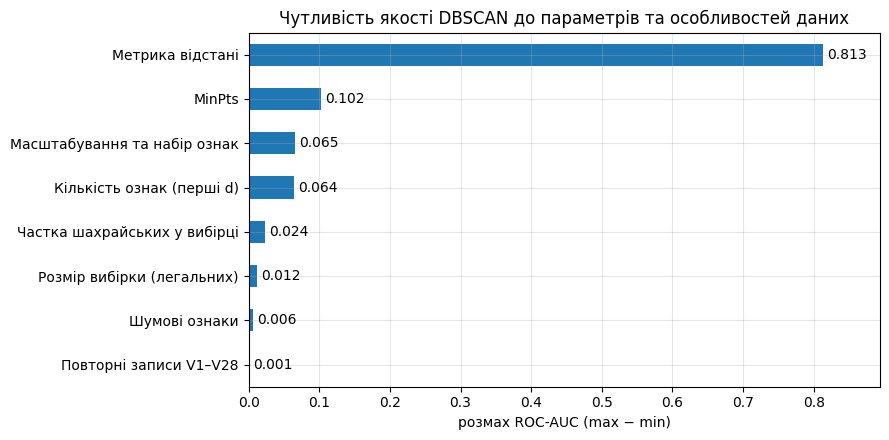

In [20]:
summary_df = pd.DataFrame({k: {"min": v.min(), "max": v.max(), "розмах": v.max() - v.min()} for k, v in FACTORS.items()}).T.sort_values("розмах")
display(summary_df.round(4))
ax = summary_df["розмах"].plot.barh(figsize=(9, 4.5), color="tab:blue")
ax.set_xlabel("розмах ROC-AUC (max − min)"); ax.set_title("Чутливість якості DBSCAN до параметрів та особливостей даних")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3); ax.margins(x=0.1); plt.tight_layout(); plt.show()

**Висновок.** Найбільший розмах ROC-AUC дає метрика відстані (0.81, через косинусну), далі `MinPts` (0.10), масштабування й набір ознак (0.065) та кількість перших компонент (0.064). Частка шахрайських (0.024) і розмір вибірки (0.012) змінюють ROC-AUC слабо, хоч і сильно змінюють precision@K; шумові ознаки (0.006) і повторні записи (0.001) майже не впливають. Отже, DBSCAN найбільш чутливий до геометрії простору (метрика, масштаб, вибір ознак) та до `MinPts`, а не до якості чи чистоти даних.

## 7. Порівняння DBSCAN з іншими детекторами викидів
Порівнюємо оцінку «шумовості» DBSCAN з іншими способами ранжувати точки за аномальністю на тих самих вибірках (3 повторення): відстань до 56-го сусіда, Isolation Forest, LOF (Local Outlier Factor) із 20 та 56 сусідами. Також наводимо логістичну регресію, навчену на мітках (5-кратна крос-валідація): це верхня межа, яку дає знання міток. Усі методи без міток отримують лише ознаки `V1`–`V28`.

,ROC-AUC,PR-AUC,precision@K,recall@5%
"DBSCAN, MinPts = 56",0.9469,0.6123,0.6307,0.6843
"DBSCAN, MinPts = 100",0.9482,0.6538,0.6963,0.7879
відстань до 56-го сусіда,0.9466,0.5509,0.5877,0.6357
Isolation Forest,0.9405,0.6888,0.6406,0.6744
"LOF, 20 сусідів",0.4855,0.0532,0.0867,0.0965
"LOF, 56 сусідів",0.5057,0.0636,0.1205,0.1268
логістична регресія (з мітками),0.9762,0.9149,0.8689,0.8802


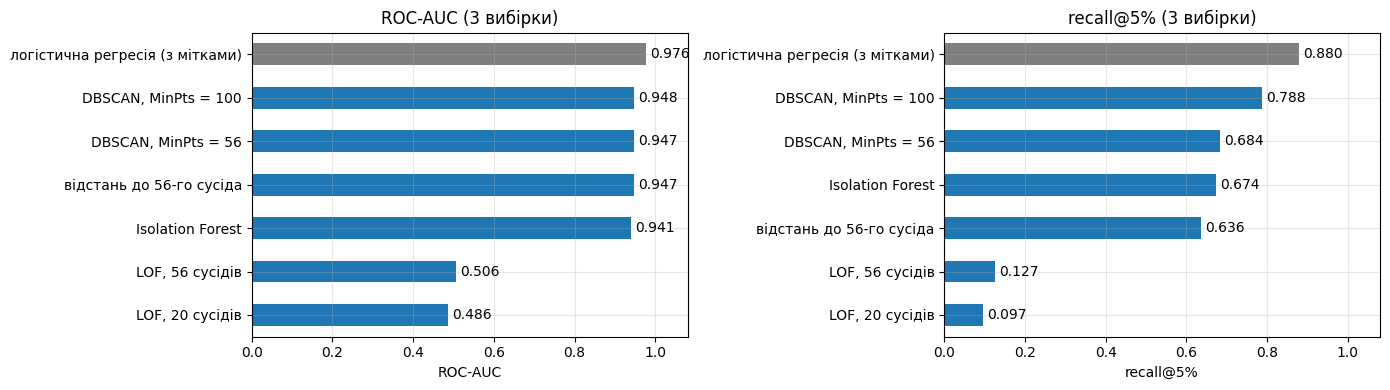

In [21]:
def detector_scores(s, seed):
    X, y = s[V].to_numpy(), s["Class"].to_numpy()
    out = {"DBSCAN, MinPts = 56": noise_score(X, 56), "DBSCAN, MinPts = 100": noise_score(X, 100),
           "відстань до 56-го сусіда": NearestNeighbors(n_neighbors=56).fit(X).kneighbors(X)[0][:, -1],
           "Isolation Forest": -IsolationForest(n_estimators=200, random_state=seed, n_jobs=2).fit(X).score_samples(X),
           "LOF, 20 сусідів": -LocalOutlierFactor(n_neighbors=20).fit(X).negative_outlier_factor_,
           "LOF, 56 сусідів": -LocalOutlierFactor(n_neighbors=56).fit(X).negative_outlier_factor_}
    Z = StandardScaler().fit_transform(s[FEATS])
    out["логістична регресія (з мітками)"] = cross_val_predict(LogisticRegression(max_iter=500, class_weight="balanced"), Z, y, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="decision_function")
    return {k: evaluate_score(v, y) for k, v in out.items()}

runs = [detector_scores(make_sample(seed=sd), sd) for sd in SEEDS]
det = pd.concat({k: pd.DataFrame({m: r[m] for m in runs[0]}).T for k, r in enumerate(runs)}).groupby(level=1).mean().loc[list(runs[0])]
display(det.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col in zip(ax, ["ROC-AUC", "recall@5%"]):
    det[col].sort_values().plot.barh(ax=a, color=["tab:blue" if "мітк" not in k else "tab:gray" for k in det[col].sort_values().index])
    a.set_xlabel(col); a.set_title(col + " (3 вибірки)"); a.bar_label(a.containers[0], fmt="%.3f", padding=3); a.set_xlim(0, 1.08)
plt.tight_layout(); plt.show()

**Висновок.** Оцінка шумовості DBSCAN за якістю не гірша за інші методи без міток: ROC-AUC 0.947 (`MinPts` = 56) та 0.948 (100) проти 0.941 у Isolation Forest; recall серед 5% найпідозріліших — 0.684 і 0.788 проти 0.674. За PR-AUC Isolation Forest трохи кращий (0.689 проти 0.612 і 0.654). Проста відстань до 56-го сусіда дає той самий ROC-AUC (0.947), але нижчий PR-AUC (0.551). LOF не працює (ROC-AUC 0.49–0.51, тобто на рівні випадкового вгадування): імовірно, локальна щільність шахрайських транзакцій не відрізняється від щільності їхніх сусідів. Логістична регресія з мітками значно краща (ROC-AUC 0.976, PR-AUC 0.915, recall 0.880), тобто мітки варто використовувати, коли вони є.

## 8. A/B-тестування моделей класифікації
A/B-тестування порівнює дві (або більше) моделі, щоб визначити кращу. За методичкою воно складається з чотирьох кроків: (1) підготовка даних і розбиття на навчальну та тестову вибірки; (2) навчання моделей; (3) оцінка метриками на тестовій вибірці; (4) вибір моделі з найвищою оцінкою. Виконуємо ці кроки для чотирьох моделей: **A** — логістична регресія, **B** — випадковий ліс, **C** — лінійний SVM, **D** — наївний Байєс. Далі перевіряємо, чи можна довіряти такому вибору: чи не є різниця між моделями випадковою, чи правильну метрику використано і яка кількість даних потрібна для надійного висновку.

### 8.1. Проста реалізація з методички та її обмеження
Функція `ab_test` порівнює середні значення двох груп і «обирає» більше. Застосовуємо її до прикладу з методички (справжні ймовірності 0.10 та 0.12, по 1000 спостережень), а потім повторюємо експеримент 2 000 разів і додатково перевіряємо випадок A/A, коли обидві групи мають однакову ймовірність 0.10 (різниці немає).

In [22]:
def ab_test(control_group, treatment_group):
    """Функція з методички: порівнює середні значення двох груп."""
    control_conversion_rate = np.mean(control_group)
    treatment_conversion_rate = np.mean(treatment_group)
    if treatment_conversion_rate > control_conversion_rate:
        return "Treatment group outperformed control group"
    elif treatment_conversion_rate < control_conversion_rate:
        return "Control group outperformed treatment group"
    else:
        return "No significant difference between groups"

rng = np.random.default_rng(RANDOM_STATE)
print("Приклад з методички:", ab_test(rng.binomial(1, 0.10, 1000), rng.binomial(1, 0.12, 1000)))

def two_prop_pvalue(x1, n1, x2, n2):
    """Двосторонній z-тест для різниці двох часток (x — кількість успіхів, n — розмір групи)."""
    p = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return 2 * (1 - stats.norm.cdf(abs(x2 / n2 - x1 / n1) / se)) if se > 0 else 1.0

R = 2000
rows = {}
for name, p_treat in [("A/B: 0.10 проти 0.12", 0.12), ("A/A: 0.10 проти 0.10", 0.10)]:
    out = [ab_test(a, b) for a, b in zip(rng.binomial(1, 0.10, (R, 1000)), rng.binomial(1, p_treat, (R, 1000)))]
    x1, x2 = rng.binomial(1000, 0.10, R), rng.binomial(1000, p_treat, R)
    rows[name] = {"«Treatment outperformed»": np.mean([o.startswith("Treatment") for o in out]),
                  "«No significant difference»": np.mean([o.startswith("No") for o in out]),
                  "статистично значуща різниця (z-тест, p < 0.05)": np.mean([two_prop_pvalue(a, 1000, b, 1000) < 0.05 for a, b in zip(x1, x2)])}
display(pd.DataFrame(rows).T.round(3))

Приклад з методички: Treatment group outperformed control group


,«Treatment outperformed»,«No significant difference»,"статистично значуща різниця (z-тест, p < 0.05)"
A/B: 0.10 проти 0.12,0.920,0.012,0.301
A/A: 0.10 проти 0.10,0.483,0.032,0.042


**Висновок.** На прикладі з методички (0.10 проти 0.12, по 1 000 спостережень) функція `ab_test` вибрала експериментальну групу, але при 2 000 повторах вона так робить у 92% випадків, тоді як z-тест знаходить значущу різницю (p < 0.05) лише у 30% — потужність тесту низька. В A/A-тесті (різниці немає) вона «визначила переможця» у 48% випадків, а відповідь «No significant difference» з'являється лише при точному збігові середніх (3%). Тому порівняння середніх без перевірки значущості показує лише випадкову різницю.

### 8.2. Кроки 1–2: підготовка даних і навчання моделей
Розбиваємо дані на навчальну та тестову вибірки (приблизно 2/3 і 1/3) зі збереженням частки шахрайських транзакцій та **за групами** (записи з однаковими `V1`–`V28` потрапляють в одну вибірку, щоб копії не «просочилися» з навчальної вибірки в тестову). Для ознак використовуємо `V1`–`V28`, `LogAmount`, `HourSin`, `HourCos` з z-оцінкою (параметри масштабування — лише за навчальною вибіркою). Усі моделі враховують дисбаланс класів: логістична регресія та SVM — через `class_weight="balanced"`, ліс — `balanced_subsample`; наївний Байєс навчається без ваг. Як оцінку «підозрілості» використовуємо ймовірність шахрайства (для SVM — відстань до гіперплощини, для наївного Байєса — логарифм відношення шансів, бо його ймовірності майже завжди 0 або 1).

In [23]:
y_all, groups = df["Class"].to_numpy(), df["group"].to_numpy()
tr_idx, te_idx = next(StratifiedGroupKFold(3, shuffle=True, random_state=RANDOM_STATE).split(df, y_all, groups))
print(f"Навчальна вибірка: {len(tr_idx)} (шахрайських {y_all[tr_idx].sum()}) | тестова: {len(te_idx)} (шахрайських {y_all[te_idx].sum()}) | груп в обох вибірках: {len(set(groups[tr_idx]) & set(groups[te_idx]))}")
scaler = StandardScaler().fit(df.loc[tr_idx, FEATS])
Xtr, Xte = scaler.transform(df.loc[tr_idx, FEATS]), scaler.transform(df.loc[te_idx, FEATS])
ytr, yte = y_all[tr_idx], y_all[te_idx]

def make_models():
    return {"A: логістична регресія": LogisticRegression(max_iter=500, class_weight="balanced"),
            "B: випадковий ліс": RandomForestClassifier(n_estimators=100, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=2, random_state=0),
            "C: лінійний SVM": LinearSVC(C=0.1, class_weight="balanced", max_iter=5000),
            "D: наївний Байєс": GaussianNB()}

def suspicion(model, X):
    """Оцінка підозрілості транзакції: чим більша, тим імовірніше шахрайство."""
    if isinstance(model, GaussianNB):
        lp = model.predict_log_proba(X); return lp[:, 1] - lp[:, 0]
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

models, scores, preds, fit_time = make_models(), {}, {}, {}
for name, m in models.items():
    t0 = time.perf_counter(); m.fit(Xtr, ytr); fit_time[name] = time.perf_counter() - t0
    scores[name], preds[name] = suspicion(m, Xte), m.predict(Xte)
print("Час навчання, с:", {k: round(v, 1) for k, v in fit_time.items()})

Навчальна вибірка: 189191 (шахрайських 321) | тестова: 94535 (шахрайських 152) | груп в обох вибірках: 0
Час навчання, с: {'A: логістична регресія': 0.9, 'B: випадковий ліс': 91.1, 'C: лінійний SVM': 1.6, 'D: наївний Байєс': 0.1}


### 8.3. Крок 3: оцінка на тестовій вибірці
Крім accuracy (яка, як побачимо, для 0.17% шахрайських транзакцій нічого не каже) рахуємо ROC-AUC, PR-AUC (середня точність; чутлива до рідкісного класу) і **recall при частці хибних тривог 0.1%** — частку знайдених шахрайських транзакцій, якщо поріг обрано так, що лише 0.1% легальних транзакцій помилково позначаються як шахрайські. Остання метрика відповідає практичній вимозі банку: помилкових блокувань має бути мало. У таблиці також наведено recall і precision за порогом, який використовує сама модель (`predict`).

Accuracy моделі, що завжди відповідає «легальна»: 0.9984


,accuracy,ROC-AUC,PR-AUC,recall при FPR 0.1%,recall при порозі моделі,precision при порозі моделі
A: логістична регресія,0.9740,0.9774,0.6996,0.8092,0.9079,0.0534
B: випадковий ліс,0.9995,0.9552,0.8178,0.8618,0.7697,0.8931
C: лінійний SVM,0.9779,0.9764,0.6997,0.8092,0.8882,0.0613
D: наївний Байєс,0.9780,0.9567,0.2146,0.2697,0.8355,0.0583


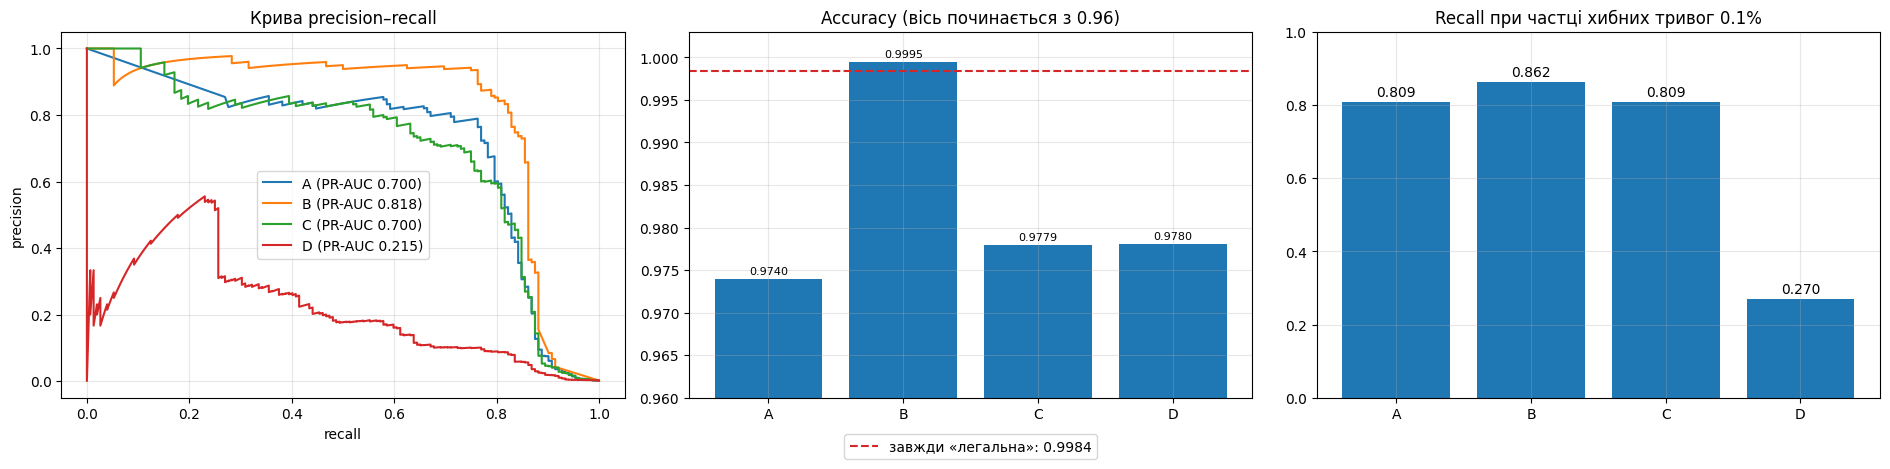

In [24]:
def recall_at_fpr(score, y, fpr=0.001):
    """Частка знайдених шахрайських транзакцій, якщо поріг відсікає лише fpr легальних; повертає також поріг."""
    thr = np.quantile(score[y == 0], 1 - fpr)
    return (score[y == 1] > thr).mean(), thr

def metrics_row(name):
    s = scores[name]
    return {"accuracy": accuracy_score(yte, preds[name]), "ROC-AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
            "recall при FPR 0.1%": recall_at_fpr(s, yte)[0], "recall при порозі моделі": preds[name][yte == 1].mean(),
            "precision при порозі моделі": precision_score(yte, preds[name], zero_division=0)}

res = pd.DataFrame({n: metrics_row(n) for n in models}).T
base_acc = 1 - yte.mean()
print(f"Accuracy моделі, що завжди відповідає «легальна»: {base_acc:.4f}")
display(res.round(4))

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for n, s in scores.items():
    p, r, _ = precision_recall_curve(yte, s); ax[0].plot(r, p, label=f"{n[0]} (PR-AUC {res.loc[n, 'PR-AUC']:.3f})")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Крива precision–recall"); ax[0].legend()
labels = [n[0] for n in models]
ax[1].bar(labels, res["accuracy"], color="tab:blue"); ax[1].axhline(base_acc, color="tab:red", ls="--", label=f"завжди «легальна»: {base_acc:.4f}")
ax[1].set_ylim(0.96, 1.003); ax[1].set_title("Accuracy (вісь починається з 0.96)"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.08)); ax[1].bar_label(ax[1].containers[0], fmt="%.4f", padding=2, fontsize=8)
ax[2].bar(labels, res["recall при FPR 0.1%"], color="tab:blue"); ax[2].set_ylim(0, 1); ax[2].set_title("Recall при частці хибних тривог 0.1%"); ax[2].bar_label(ax[2].containers[0], fmt="%.3f", padding=2)
plt.tight_layout(); plt.show()

**Висновок.** Модель, що завжди відповідає «легальна», має accuracy 0.9983: вища за всі моделі, крім B (0.9995); A, C та D мають 0.975–0.980, бо через ваги класів дають 2–2.5% хибних тривог (precision при порозі моделі лише 0.056, 0.070 та 0.060, тобто ≈ 1 з 14–18 позначених справді шахрайська). Ліс має recall 0.779 при precision 0.939. Метрики вибирають різних переможців: за ROC-AUC кращі A та C (0.974) проти B (0.941), за PR-AUC та recall при FPR 0.1% — B (0.823 та 0.854 проти 0.68 та 0.81 в A і C). ROC-AUC враховує всі пороги, а банку важливий лише дуже малий рівень хибних тривог, тому для цієї задачі корисніші PR-AUC та recall при заданому FPR. Наївний Байєс найгірший (PR-AUC 0.207, recall 0.266). Ліс навчається найдовше (≈ 37 с проти 0.1–0.8 с).

### 8.4. Крок 4 і його перевірка: чи значуща різниця між моделями?
За методичкою тут просто беремо модель із найвищою оцінкою. Але тестова вибірка містить лише 158 шахрайських транзакцій, тому оцінка метрики має велику похибку. Перевіряємо це трьома способами, усі — на **одній і тій самій тестовій вибірці** (парні порівняння):
- **Bootstrap**: 1 000 разів випадково перебираємо тестові транзакції з поверненням, на кожній вибірці рахуємо PR-AUC та recall при FPR 0.1%; отримуємо 95% довірчі інтервали та розподіл різниці між моделями. $p$-значення — частка повторень, у яких різниця має протилежний знак (подвоєна, двостороння).
- **Тест Мак-Немара**: серед шахрайських транзакцій рахуємо ті, які знайшла лише одна з двох моделей (при порозі FPR 0.1%), і перевіряємо точним біноміальним тестом, чи ці числа відрізняються від рівних.
- **Поправка Холма** на 6 парних порівнянь, бо при багатьох порівняннях імовірність випадково «знайти» різницю зростає.

In [25]:
order = {n: np.argsort(-scores[n], kind="stable") for n in models}
ysort = {n: yte[order[n]] for n in models}

def ap_weighted(ys, c):
    """Середня точність (PR-AUC) для вибірки з кратностями c; ys — мітки, відсортовані за спаданням оцінки."""
    cy = c * ys; tp = np.cumsum(cy); fp = np.cumsum(c - cy)
    return (cy * tp / np.maximum(tp + fp, 1)).sum() / cy.sum()

def tpr_at_fpr_weighted(ys, c, fpr=0.001):
    pos, neg = c * ys, c * (1 - ys)
    i = np.searchsorted(np.cumsum(neg) / neg.sum(), fpr, side="right")
    return np.cumsum(pos)[max(i - 1, 0)] / pos.sum()

B, n_te = 1000, len(yte)
boot_rng = np.random.default_rng(RANDOM_STATE)
boot = {n: {"PR-AUC": np.empty(B), "recall при FPR 0.1%": np.empty(B)} for n in models}
for b in range(B):
    counts = np.bincount(boot_rng.integers(0, n_te, n_te), minlength=n_te)         # кратності тестових транзакцій у новій вибірці
    for n in models:
        c = counts[order[n]]
        boot[n]["PR-AUC"][b], boot[n]["recall при FPR 0.1%"][b] = ap_weighted(ysort[n], c), tpr_at_fpr_weighted(ysort[n], c)

ci = pd.DataFrame({(m, n[0]): {"оцінка": res.loc[n, m], "2.5%": np.percentile(boot[n][m], 2.5), "97.5%": np.percentile(boot[n][m], 97.5)}
                   for m in ["PR-AUC", "recall при FPR 0.1%"] for n in models}).T
display(ci.round(3))

def holm(p):
    """Поправка Холма: скориговані p-значення для списку p."""
    p = np.asarray(p, float); idx = np.argsort(p); adj = np.empty(len(p)); run = 0.0
    for r, i in enumerate(idx):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

pairs = [(a, b) for i, a in enumerate(models) for b in list(models)[i + 1:]]
caught = {n: scores[n][yte == 1] > recall_at_fpr(scores[n], yte)[1] for n in models}
rows = []
for a, b in pairs:
    row = {"пара": f"{a[0]} – {b[0]}"}
    for m in ["PR-AUC", "recall при FPR 0.1%"]:
        d = boot[b][m] - boot[a][m]
        row[f"Δ {m} (друга − перша)"] = d.mean()
        row[f"95% ІІ Δ {m}"] = f"[{np.percentile(d, 2.5):+.3f}; {np.percentile(d, 97.5):+.3f}]"
        row[f"p bootstrap, {m}"] = min(1.0, 2 * (min((d <= 0).sum(), (d >= 0).sum()) + 1) / (B + 1))
    only_a, only_b = int((caught[a] & ~caught[b]).sum()), int((~caught[a] & caught[b]).sum())
    row["лише перша / лише друга"] = f"{only_a} / {only_b}"
    row["p Мак-Немара"] = stats.binomtest(only_b, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    rows.append(row)
pair_df = pd.DataFrame(rows).set_index("пара")
for col in ["p bootstrap, PR-AUC", "p bootstrap, recall при FPR 0.1%", "p Мак-Немара"]:
    pair_df[col + " (Холм)"] = holm(pair_df[col])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(pair_df.round(4))

оцінка   2.5%  97.5%
PR-AUC              A   0.700  0.598  0.768
                    B   0.818  0.751  0.882
                    C   0.700  0.622  0.771
                    D   0.215  0.162  0.291
recall при FPR 0.1% A   0.809  0.746  0.872
                    B   0.862  0.800  0.915
                    C   0.809  0.737  0.868
                    D   0.270  0.205  0.357

,Δ PR-AUC (друга − перша),95% ІІ Δ PR-AUC,"p bootstrap, PR-AUC",Δ recall при FPR 0.1% (друга − перша),95% ІІ Δ recall при FPR 0.1%,"p bootstrap, recall при FPR 0.1%",лише перша / лише друга,p Мак-Немара,"p bootstrap, PR-AUC (Холм)","p bootstrap, recall при FPR 0.1% (Холм)",p Мак-Немара (Холм)
пара,,,,,,,,,,,
A – B,0.1359,[+0.061; +0.208],0.0040,0.0499,[+0.018; +0.090],0.0060,0 / 8,0.0078,0.0120,0.0180,0.0234
A – C,0.0174,[-0.011; +0.046],0.1978,-0.0052,[-0.032; +0.019],0.9311,1 / 1,1.0000,0.1978,0.9311,1.0000
A – D,-0.4610,[-0.535; -0.387],0.0020,-0.5326,[-0.617; -0.444],0.0020,84 / 2,0.0000,0.0120,0.0120,0.0000
B – C,-0.1185,[-0.178; -0.057],0.0040,-0.0551,[-0.103; -0.015],0.0060,9 / 1,0.0215,0.0120,0.0180,0.0430
B – D,-0.5969,[-0.664; -0.526],0.0020,-0.5825,[-0.669; -0.500],0.0020,90 / 0,0.0000,0.0120,0.0120,0.0000
C – D,-0.4784,[-0.539; -0.416],0.0020,-0.5274,[-0.615; -0.440],0.0020,84 / 2,0.0000,0.0120,0.0120,0.0000


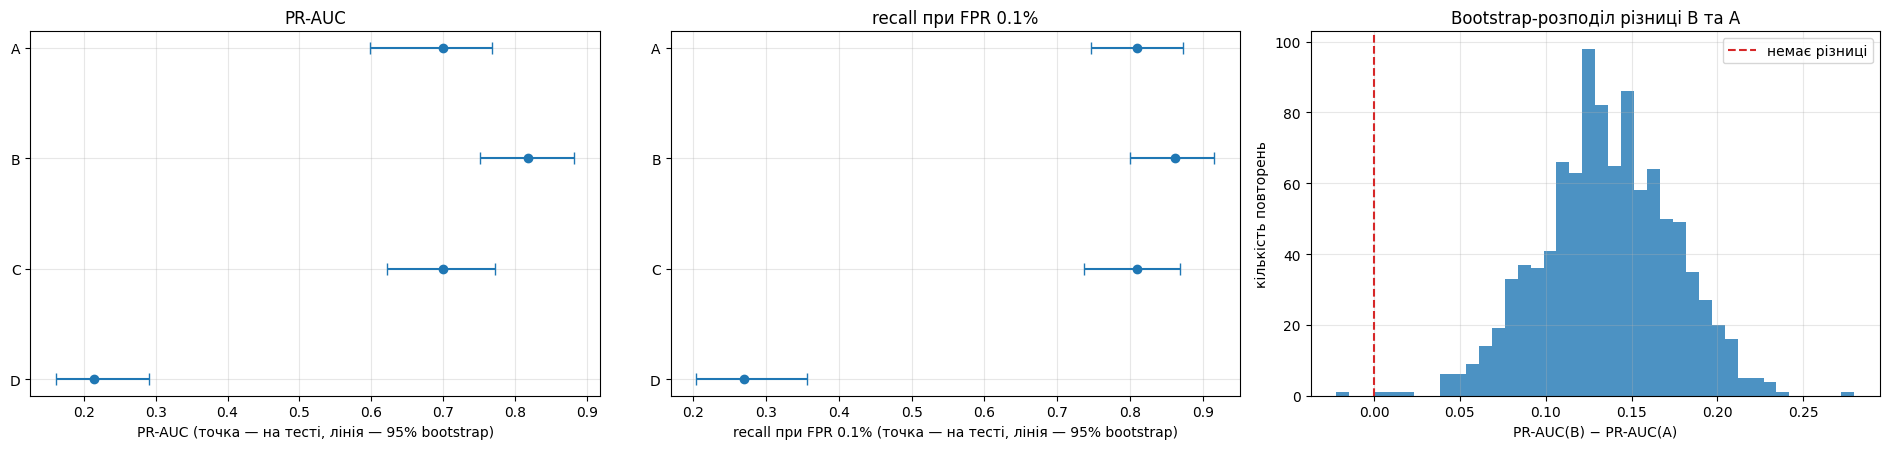

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
for a, m in zip(ax[:2], ["PR-AUC", "recall при FPR 0.1%"]):
    for k, n in enumerate(models):
        a.errorbar(res.loc[n, m], k, xerr=[[res.loc[n, m] - np.percentile(boot[n][m], 2.5)], [np.percentile(boot[n][m], 97.5) - res.loc[n, m]]], fmt="o", capsize=4, color="tab:blue")
    a.set_yticks(range(len(models))); a.set_yticklabels([n[0] for n in models]); a.invert_yaxis(); a.set_xlabel(m + " (точка — на тесті, лінія — 95% bootstrap)"); a.set_title(m)
dBA = boot["B: випадковий ліс"]["PR-AUC"] - boot["A: логістична регресія"]["PR-AUC"]
ax[2].hist(dBA, bins=40, color="tab:blue", alpha=0.8); ax[2].axvline(0, color="tab:red", ls="--", label="немає різниці")
ax[2].set_xlabel("PR-AUC(B) − PR-AUC(A)"); ax[2].set_ylabel("кількість повторень"); ax[2].set_title("Bootstrap-розподіл різниці B та A"); ax[2].legend()
plt.tight_layout(); plt.show()

**Висновок.** Тест містить лише 158 шахрайських транзакцій, тому довірчі інтервали широкі: PR-AUC A — 0.682 [0.574; 0.762], B — 0.823 [0.752; 0.884], C — 0.677 [0.587; 0.758], D — 0.207 [0.151; 0.278]. Інтервали A і B перекриваються, але парна різниця B − A (на тесті +0.141, середнє за bootstrap +0.151) має інтервал [+0.082; +0.225], що нуль не містить (p = 0.002, після поправки Холма 0.012). За recall при FPR 0.1% різниця B − A = +0.044 [+0.008; +0.073] (p = 0.008, Холм 0.016); за тестом Мак-Немара ліс знайшов 7 шахрайських транзакцій, які пропустила логістична регресія, а вона — жодної, якої б не знайшов ліс (p = 0.016, Холм 0.047). A і C не відрізняються (різниця PR-AUC ≈ 0.004, інтервал [−0.018; +0.030], Мак-Немар 3 проти 3), D значущо гірша за всі інші (Холм ≤ 0.012). Ці тести враховують лише випадковість тестової вибірки при одному поділі й одних навчених моделях, а не мінливість навчання.

### 8.5. Повторні розбиття: тест 5×2cv
Один поділ на навчальну/тестову вибірку дає лише одну оцінку, яка залежить від того, як пощастило з поділом. Тому застосуємо **5×2cv парний t-тест (Дітеріх)**: п'ять разів випадково ділимо дані навпіл (за групами), кожна половина по черзі є навчальною та тестовою; різниці PR-AUC між двома моделями $d^{(i)}_j$ ($i$ — повторення, $j$ — половина) дають статистику $t = d^{(1)}_1 / \sqrt{\tfrac15\sum_i s_i^2}$, де $s_i^2$ — вибіркова дисперсія двох різниць повторення $i$; вона має розподіл Стьюдента з 5 ступенями свободи. Щоб тест виконувався за розумний час, беремо підвибірку: усі шахрайські та 60 000 випадкових легальних транзакцій (частка шахрайських ≈ 0.8%, тому PR-AUC тут вищі за ті, що були на повному тесті).

In [27]:
rng5 = np.random.default_rng(RANDOM_STATE)
sub = np.r_[df.index[df.Class == 1].to_numpy(), rng5.choice(df.index[df.Class == 0].to_numpy(), 60_000, replace=False)]
Xs, ys_, gs = df.loc[sub, FEATS].to_numpy(), df.loc[sub, "Class"].to_numpy(), df.loc[sub, "group"].to_numpy()

t0 = time.perf_counter()
pr_cv = {n: [] for n in models}
for rep in range(5):
    for fit_i, test_i in StratifiedGroupKFold(2, shuffle=True, random_state=rep).split(Xs, ys_, gs):     # дві половини по черзі: навчання / тест
        sc_ = StandardScaler().fit(Xs[fit_i])
        for n, m in make_models().items():
            m.fit(sc_.transform(Xs[fit_i]), ys_[fit_i])
            pr_cv[n].append(average_precision_score(ys_[test_i], suspicion(m, sc_.transform(Xs[test_i]))))
print(f"Час 5×2cv: {time.perf_counter() - t0:.0f} с")

Час 5×2cv: 156 с


Середній PR-AUC за 10 оцінками: {'A': 0.824, 'B': 0.87, 'C': 0.811, 'D': 0.44}


,Δ PR-AUC (перша − друга),t,p (5×2cv),p (Холм)
пара,,,,
A – B,-0.0464,-3.0580,0.0282,0.0563
A – C,0.0130,1.4636,0.2032,0.2032
A – D,0.3845,7.6934,0.0006,0.0030
B – C,0.0594,4.2343,0.0082,0.0246
B – D,0.4309,9.5717,0.0002,0.0013
C – D,0.3715,7.5219,0.0007,0.0030


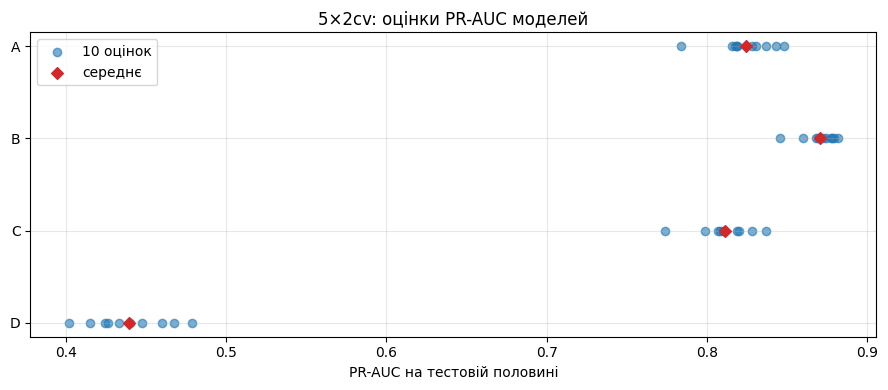

In [28]:
PR5 = {n: np.array(v).reshape(5, 2) for n, v in pr_cv.items()}         # [повторення, половина]

def cv52_test(a, b):
    """5×2cv парний t-тест Дітеріха: статистика та двостороннє p-значення (5 ступенів свободи)."""
    diff = PR5[a] - PR5[b]
    s2 = ((diff - diff.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
    t = diff[0, 0] / np.sqrt(s2.mean())
    return t, 2 * (1 - stats.t.cdf(abs(t), 5))

print("Середній PR-AUC за 10 оцінками:", {n[0]: round(float(v.mean()), 3) for n, v in PR5.items()})
cv_rows = []
for a, b in pairs:
    t, p = cv52_test(a, b)
    cv_rows.append({"пара": f"{a[0]} – {b[0]}", "Δ PR-AUC (перша − друга)": (PR5[a] - PR5[b]).mean(), "t": t, "p (5×2cv)": p})
cv_df = pd.DataFrame(cv_rows).set_index("пара")
cv_df["p (Холм)"] = holm(cv_df["p (5×2cv)"])
display(cv_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
for k, n in enumerate(models):
    ax.scatter(PR5[n].ravel(), np.full(10, k), color="tab:blue", alpha=0.6, label="10 оцінок" if k == 0 else None)
    ax.scatter(PR5[n].mean(), k, marker="D", color="tab:red", zorder=3, label="середнє" if k == 0 else None)
ax.set_yticks(range(len(models))); ax.set_yticklabels([n[0] for n in models]); ax.invert_yaxis(); ax.set_xlabel("PR-AUC на тестовій половині"); ax.set_title("5×2cv: оцінки PR-AUC моделей"); ax.legend()
plt.tight_layout(); plt.show()

**Висновок.** Середній PR-AUC за 10 оцінками: A 0.828, B 0.874, C 0.821, D 0.437 (вищі, ніж у п. 8.3, бо в підвибірці шахрайських ≈ 0.8%). Ліс у середньому кращий за A на 0.045, але 5×2cv не підтверджує цього: p = 0.090 (з поправкою Холма 0.18). B проти C: p = 0.036, але після поправки 0.109 — теж незначуще. A та C не відрізняються (p = 0.96), D гірша за всі (Холм ≤ 0.0002). Тест, що враховує зміну навчальних даних, консервативніший: 5 ступенів свободи та лише ≈ 236 шахрайських у кожній половині не дають достатньої потужності, тоді як bootstrap і Мак-Немар цього не враховують.

### 8.6. A/B-тест із незалежними групами: скільки даних потрібно
У реальному A/B-тесті **різні групи** об'єктів обробляє різна модель, і порівнюються частки успіхів у групах. Моделюємо це на тестових даних: кожну шахрайську транзакцію тестової вибірки випадково (з ймовірністю 0.5) відносимо до однієї з двох груп (у середньому по 79); групу «контроль» обслуговує модель A (логістична регресія), групу «експеримент» — модель B (випадковий ліс); успіхом вважаємо виявлення шахрайської транзакції при порозі FPR 0.1% (поріг фіксуємо на легальних транзакціях тесту). Різницю часток перевіряємо двостороннім z-тестом для двох часток. Повторюємо 3 000 випадкових поділів. Для контролю хибних спрацювань проводимо **A/A-тест**: в обох групах працює та сама модель A, значущих різниць бути не має (очікуємо ≈ 5% при $\alpha=0.05$). Потрібну кількість спостережень у групі оцінюємо за формулою
$$n=\frac{(z_{1-\alpha/2}+z_{1-\beta})^2\,(p_1(1-p_1)+p_2(1-p_2))}{(p_1-p_2)^2},$$
де $p_1,p_2$ — частки виявлених транзакцій, $\alpha=0.05$, потужність $1-\beta=0.8$.

Частка знайдених шахрайських (поріг FPR 0.1%): A = 0.809, B = 0.862; шахрайських у тесті: 152
Потужність A/B-тесту при 76 шахрайських транзакціях у групі (частка p < 0.05): 0.124
Хибні спрацювання в A/A-тесті (частка p < 0.05): 0.047
Частка поділів, у яких група B виявилась кращою за групу A: 0.829
Потрібна кількість шахрайських транзакцій у кожній групі (формула): 775


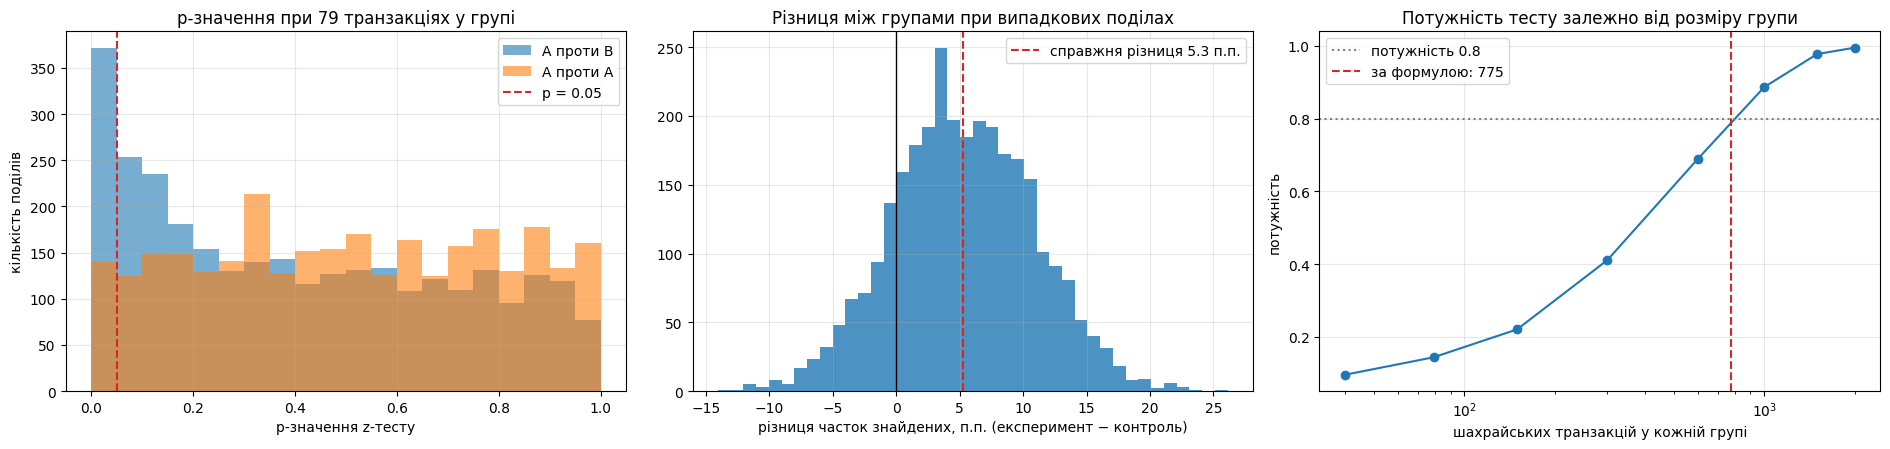

транзакцій у групі,40,79,150,300,600,1000,1500,2000
потужність,0.096,0.144,0.221,0.411,0.689,0.886,0.977,0.995


In [29]:
nameA, nameB = "A: логістична регресія", "B: випадковий ліс"
fraud_idx = np.flatnonzero(yte == 1)
hitA, hitB = caught[nameA], caught[nameB]                       # чи знайдено кожну шахрайську транзакцію тесту (порядок збігається з fraud_idx)
pA, pB = hitA.mean(), hitB.mean()
print(f"Частка знайдених шахрайських (поріг FPR 0.1%): A = {pA:.3f}, B = {pB:.3f}; шахрайських у тесті: {len(fraud_idx)}")

sim_rng = np.random.default_rng(RANDOM_STATE)
R = 3000
pv_ab, pv_aa, pos_ab = np.empty(R), np.empty(R), np.empty(R)
for r in range(R):
    in_b = sim_rng.random(len(fraud_idx)) < 0.5                                # кожну транзакцію випадково відносимо до експериментальної групи
    n_ctrl, n_exp = (~in_b).sum(), in_b.sum()
    pv_ab[r] = two_prop_pvalue(hitA[~in_b].sum(), n_ctrl, hitB[in_b].sum(), n_exp)
    pv_aa[r] = two_prop_pvalue(hitA[~in_b].sum(), n_ctrl, hitA[in_b].sum(), n_exp)
    pos_ab[r] = hitB[in_b].mean() - hitA[~in_b].mean()

def required_n(p1, p2, alpha=0.05, power=0.8):
    return (stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2

n_group = len(fraud_idx) // 2
sim_power = {n: np.mean([two_prop_pvalue(a, n, b, n) < 0.05 for a, b in zip(sim_rng.binomial(n, pA, 3000), sim_rng.binomial(n, pB, 3000))]) for n in [40, 79, 150, 300, 600, 1000, 1500, 2000]}
print(f"Потужність A/B-тесту при {n_group} шахрайських транзакціях у групі (частка p < 0.05): {(pv_ab < 0.05).mean():.3f}")
print(f"Хибні спрацювання в A/A-тесті (частка p < 0.05): {(pv_aa < 0.05).mean():.3f}")
print(f"Частка поділів, у яких група B виявилась кращою за групу A: {(pos_ab > 0).mean():.3f}")
print(f"Потрібна кількість шахрайських транзакцій у кожній групі (формула): {required_n(pA, pB):.0f}")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
bins = np.linspace(0, 1, 21)
ax[0].hist(pv_ab, bins=bins, alpha=0.6, color="tab:blue", label="A проти B"); ax[0].hist(pv_aa, bins=bins, alpha=0.6, color="tab:orange", label="A проти A")
ax[0].axvline(0.05, color="tab:red", ls="--", label="p = 0.05"); ax[0].set_xlabel("p-значення z-тесту"); ax[0].set_ylabel("кількість поділів"); ax[0].set_title("p-значення при 79 транзакціях у групі"); ax[0].legend()
ax[1].hist(pos_ab * 100, bins=40, color="tab:blue", alpha=0.8); ax[1].axvline((pB - pA) * 100, color="tab:red", ls="--", label=f"справжня різниця {100 * (pB - pA):.1f} п.п."); ax[1].axvline(0, color="black", lw=1)
ax[1].set_xlabel("різниця часток знайдених, п.п. (експеримент − контроль)"); ax[1].set_title("Різниця між групами при випадкових поділах"); ax[1].legend()
ax[2].plot(list(sim_power), list(sim_power.values()), marker="o", color="tab:blue"); ax[2].axhline(0.8, color="tab:gray", ls=":", label="потужність 0.8")
ax[2].axvline(required_n(pA, pB), color="tab:red", ls="--", label=f"за формулою: {required_n(pA, pB):.0f}"); ax[2].set_xscale("log")
ax[2].set_xlabel("шахрайських транзакцій у кожній групі"); ax[2].set_ylabel("потужність"); ax[2].set_title("Потужність тесту залежно від розміру групи"); ax[2].legend()
plt.tight_layout(); plt.show()
display(pd.Series(sim_power, name="потужність").rename_axis("транзакцій у групі").round(3).to_frame().T)

**Висновок.** Якщо групи незалежні і по ≈ 79 шахрайських транзакцій у кожній, частки знайдених 0.810 (A) та 0.854 (B) різняться на 4.4 п.п., але z-тест виявляє це лише у 10.8% поділів (потужність), а різниця між групами в поділах коливається приблизно від −19 до +23 п.п.: у 22% поділів група B навіть не виглядає кращою за A. A/A-тест дає 4.6% значущих результатів, тобто тест калібрований (очікується ≈ 5%). За формулою для потужності 0.8 потрібно ≈ 1 112 шахрайських транзакцій у кожній групі (≈ 14 разів більше, ніж у тесті); симуляція підтверджує: потужність 0.12 при 79, 0.29 при 300, 0.53 при 600, 0.74 при 1 000, 0.90 при 1 500 та 0.96 при 2 000. Враховуючи частку шахрайських 0.17%, це близько 0.67 млн транзакцій у групі. Парне порівняння на тих самих транзакціях (Мак-Немар) виявило різницю при тих самих 158 шахрайських, бо усуває варіацію між транзакціями.

### 8.7. Підсумок A/B-тестування
Зводимо результати всіх підходів для порівняння найкращої моделі (B, випадковий ліс) з кожною з інших: `+` — різниця на користь B статистично значуща (скоригований p < 0.05), `–` — незначуща.

In [30]:
def mark(p):
    return f"p = {p:.3f} " + ("(+)" if p < 0.05 else "(–)")

summ = {}
for other in [n for n in models if n != nameB]:
    key = " – ".join(sorted([other[0], nameB[0]]))                    # так названо пари в таблицях вище
    summ[f"B проти {other[0]}"] = {"Δ PR-AUC на тесті": res.loc[nameB, "PR-AUC"] - res.loc[other, "PR-AUC"],
                                   "bootstrap PR-AUC (Холм)": mark(pair_df.loc[key, "p bootstrap, PR-AUC (Холм)"]),
                                   "Мак-Немар (Холм)": mark(pair_df.loc[key, "p Мак-Немара (Холм)"]),
                                   "5×2cv (Холм)": mark(cv_df.loc[key, "p (Холм)"])}
display(pd.DataFrame(summ).T)

,Δ PR-AUC на тесті,bootstrap PR-AUC (Холм),Мак-Немар (Холм),5×2cv (Холм)
B проти A,0.118118,p = 0.012 (+),p = 0.023 (+),p = 0.056 (–)
B проти C,0.118011,p = 0.012 (+),p = 0.043 (+),p = 0.025 (+)
B проти D,0.603162,p = 0.012 (+),p = 0.000 (+),p = 0.001 (+)


**Висновок.** Модель D (наївний Байєс) гірша за B за всіма тестами. Перевага B (ліс) над A та C за PR-AUC і тестом Мак-Немара значуща (Холм 0.012 та 0.047), але 5×2cv її не підтверджує (0.18 та 0.11). Отже, за методичкою обираємо B (PR-AUC 0.823, recall при FPR 0.1% 0.854, precision 0.94 при порозі моделі), але перевагу над A та C слід вважати ймовірною, а не доведеною: потрібно більше шахрайських транзакцій у тесті або повторні розбиття.

## 9. Переваги та недоліки

**DBSCAN — переваги**
1. Не потребує міток і кількості кластерів, а шум є безпосереднім результатом: при ε = 5 шум із 802 точок містить 399 із 473 шахрайських транзакцій (recall 0.844, 49.8% шахрайських проти 4.5% у вибірці).
2. Якість на рівні відомих детекторів без міток: ROC-AUC 0.947–0.948 проти 0.941 в Isolation Forest, recall серед 5% найпідозріліших — 0.68–0.79 проти 0.67.
3. Стійкий до зайвих ознак та повторів: 56 шумових ознак знизили ROC-AUC лише з 0.947 до 0.941, видалення копій — до 0.946; евклідова, манхеттенська та Чебишова відстані дають 0.945–0.947.
4. Проста ідея з прозорими параметрами; реалізація легко перевіряється (ARI = 1 порівняно з `sklearn`).

**DBSCAN — недоліки**
1. Чутливий до ε: при зміні ε з 3 до 16 recall падає з 0.94 до 0.20, а precision зростає з 0.13 до 0.86; ліктем кривої k-відстаней (ε = 9.3) знаходить лише 25.6% шахрайських.
2. Чутливий до `MinPts`, масштабу й метрики: ROC-AUC 0.846 при `MinPts` = 3 проти 0.948 при 100; стандартизація знижує його до 0.937, `Amount` без масштабування — до 0.882, косинусна відстань дає 0.135 (інвертоване ранжування).
3. Квадратична складність: на 20 473 точках ≈ 8 с, час зростає ≈ у 5 разів при подвоєнні легальних транзакцій; методична реалізація на 800 точках працює ≈ 27 с. На всіх 283 тис. записів потрібна вибірка або індекс сусідів.
4. Якість для користувача залежить від частки аномалій: при реальній частці 0.2% precision@K лише 0.27, при 4.5% — 0.63.
5. Не замінює навчання з мітками: логістична регресія має ROC-AUC 0.976 і PR-AUC 0.915 проти 0.947 і 0.61–0.65 у DBSCAN.

**A/B-тестування — переваги**
1. Простий порядок із чотирьох кроків дозволяє порівнювати будь-які моделі за обраною метрикою на одних даних.
2. Парні тести на одній тестовій вибірці (bootstrap, Мак-Немар) виявили перевагу лісу над логістичною регресією на 158 шахрайських транзакціях (7 проти 0, p = 0.016), хоча незалежні групи такого розміру мали б потужність лише 0.11.
3. Статистичні тести показують і відсутність різниці: A і C — різниця PR-AUC ≈ 0.004, Мак-Немар 3 проти 3 (p = 1), 5×2cv p = 0.96.
4. A/A-тест підтверджує коректність процедури: 4.6% значущих результатів при α = 0.05.

**A/B-тестування — недоліки**
1. Порівняння середніх (`ab_test`) завжди називає переможця: 92% при справжній різниці 0.10 проти 0.12 і 48% при її відсутності; значущою ж різниця була лише у 30% та 4% випадків.
2. Результат залежить від метрики: accuracy найкраща в B (0.9995), але для A, C, D (0.975–0.980) нижча за 0.9983 моделі «завжди легальна»; за ROC-AUC перемагають A та C (0.974), за PR-AUC — B (0.823).
3. При рідкісному класі потрібно дуже багато даних: на 158 шахрайських довірчі інтервали PR-AUC мають ширину 0.13–0.19, а для A/B із незалежними групами потрібно ≈ 1 112 шахрайських у групі (≈ 0.67 млн транзакцій).
4. Різні тести дають різні відповіді: bootstrap і Мак-Немар значущі (Холм 0.012–0.047), 5×2cv — ні (0.11–0.18); при кількох порівняннях потрібна поправка (Холма).
5. Один поділ даних враховує лише випадковість тесту; повторні розбиття дорожчі (ліс навчається ≈ 37 с проти 0.1–0.8 с в інших моделей).


## 10. Загальні висновки

1. Реалізовано алгоритм DBSCAN, який дає ті самі результати, що й методична реалізація та `sklearn` (ARI = 1, однакові множини шуму), але на 800 точках працює ≈ 27 с → ≈ 0.01 с. Запропоновано оцінку шумовості $s_i$ = найменше ε, за якого точка вже не є шумом: вона точно збігається з DBSCAN і дозволяє оцінити якість для всіх ε за один прохід.
2. На транзакціях ULB (283 726 після видалення дублікатів, 473 шахрайські) DBSCAN без міток працює як детектор викидів: при ε = 5 і `MinPts` = 56 шум (7.7% вибірки) містить 84% шахрайських транзакцій з precision 0.50; за ранжуванням $s_i$ ROC-AUC 0.947 — на рівні Isolation Forest (0.941), а LOF не працює (≈ 0.5).
3. Найсильніше на якість впливають метрика відстані, `MinPts`, масштабування й набір ознак (розмах ROC-AUC 0.81, 0.10, 0.065); найкраще — вихідні `V1`–`V28` без стандартизації, `MinPts` 20–400, евклідова/манхеттенська відстань. Шумові ознаки та повторні записи майже не впливають (0.006 та 0.001). Підбір ε за «ліктем» (9.3) для цієї задачі непридатний: знайдено лише 25.6% шахрайських.
4. У A/B-тестуванні чотирьох моделей кращою за PR-AUC (0.823) та recall при FPR 0.1% (0.854) є випадковий ліс; логістична регресія та SVM мають PR-AUC 0.68 і recall 0.81, наївний Байєс — 0.207 та 0.266. Accuracy (0.9983 у моделі «завжди легальна») і ROC-AUC для вибору моделі непридатні: перша віддає перевагу тривіальній поведінці, друга — A та C.
5. Перевірка значущості показала, що перевага лісу над A та C підтверджується bootstrap та тестом Мак-Немара (Холм 0.012–0.047), але не підтверджується 5×2cv (0.11–0.18): правильно вважати її ймовірною. Різниця з наївним Байєсом значуща в усіх тестах.
6. Потужність A/B-тесту з незалежними групами при 79 шахрайських транзакціях у групі лише ≈ 0.11 (A/A-перевірка 4.6% при α = 0.05); для потужності 0.8 потрібно ≈ 1 112 шахрайських на групу (≈ 0.67 млн транзакцій). Тому для рідкісних подій моделі порівнюють на одних і тих самих даних парними тестами, а справжні A/B-тести запускають лише з достатнім розміром груп.
7. Обмеження: ознаки анонімізовані (PCA), шахрайських транзакцій лише 473 (158 у тесті); DBSCAN оцінено на вибірці з 10 473 точок зі збагаченою часткою шахрайських (4.5%, у реальності 0.17%), тому precision завищений; 5×2cv виконано на підвибірці; A/B-тест змодельовано на тестових даних, а не в реальній системі; час роботи залежить від машини.
